# Sport Image Classification — CNN Transfer Learning / Fine-tuning
**DADS7202 Deep Learning (1/2569), GSAS NIDA — Programming Homework**

- **Classes (10):** badminton, basketball, boxing, chess, formula1, ice_hockey, shooting, swimming, motogp, fencing
- **Backbones (3 architectures):** VGG16, MobileNetV2, ResNet50 (ImageNet pre-trained)
- **The notebook follows the sections of HOMEWORK_GUIDELINE:**
  1. Dataset description (sources, EDA, imbalance) → 2. Data preparation (preprocessing, split, augmentation) → 3. Model architecture → 4. Training method (+ W&B Sweep) → 5. Evaluation metrics → 6. Experimental results (mean ± SD, p-value) → 7. Discussion (Grad-CAM, eyeball analysis, error analysis, frozen vs. fine-tuning ablation)

**How to use:** put the images in `sport_dataset/<class_name>/*.jpg` (folder names must match the class names above), then run the cells in order (a GPU such as a Colab T4 is recommended).
**After a kernel restart:** simply run all cells again — the cleaned data / split, the sweeps and the final runs are cached in `outputs/` and are skipped when already done. Set `REBUILD_DATA = True` only if the raw dataset has changed.

# 0. Setup

In [1]:
%pip install -q torchinfo grad-cam wandb python-dotenv scikit-learn scipy pandas tqdm opencv-python-headless

You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


In [2]:
import os, sys, json, time, copy, gc, random, hashlib, pickle, contextlib, shutil, math
os.environ.setdefault('PYTORCH_ENABLE_MPS_FALLBACK', '1')   # Apple Silicon: fall back to CPU for any op MPS lacks (must be set BEFORE importing torch)
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torchvision.transforms.v2 as T
import torchinfo

from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             precision_recall_fscore_support, confusion_matrix)
from scipy import stats

print(f"Python {sys.version.split()[0]} | PyTorch {torch.__version__} | torchvision {torchvision.__version__}")

/Users/administrator/Library/Python/3.9/lib/python/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Python 3.9.6 | PyTorch 2.8.0 | torchvision 0.23.0


In [3]:
# ------------------------- Global configuration -------------------------
CLASSES = ['badminton', 'basketball', 'boxing', 'chess', 'formula1',
           'ice_hockey', 'shooting', 'swimming', 'motogp', 'fencing']
CLASSES = sorted(CLASSES)                       # fixed order -> class index
K = len(CLASSES)
class_to_idx = {c: i for i, c in enumerate(CLASSES)}

DATA_DIR  = Path('sport_dataset')               # raw images: DATA_DIR/<class>/*.jpg
CLEAN_DIR = Path('sport_clean')                 # cleaned + resized copy (created in Section 2.1)
OUT_DIR   = Path('outputs')                     # checkpoints, results, figures
for d in [OUT_DIR, OUT_DIR/'ckpt', OUT_DIR/'figs']:
    d.mkdir(parents=True, exist_ok=True)

ARCHS       = ['vgg16', 'mobilenet_v2', 'resnet50']
IMG_SIZE    = 224
BATCH_SIZE  = 32
EPOCHS      = 12                                # same for sweep and final runs
SEEDS       = [0, 1, 2, 3, 4]                   # guideline: repeat 3-10 times (mean±SD)
SWEEP_SEED  = 42
SWEEP_COUNT = 10                                # W&B sweep runs per architecture AND per strategy (reduce if GPU time is limited)
BACKBONE_LR_MULT = 0.1                          # LR multiplier for the unfrozen backbone block
SPLIT_SEED  = 42
NUM_WORKERS = 2

RUN_SWEEP    = True                             # False -> use DEFAULT_CFG below (no W&B sweep)
USE_WANDB    = True
REBUILD_DATA = False                            # True -> re-clean / re-split even if outputs/splits.csv exists (invalidates cached results!)
REMOVE_NEAR_DUPLICATES = False                  # True -> also drop near-duplicate images (perceptual hash) before splitting; needs REBUILD_DATA = True on an existing dataset
NEAR_DUP_MAX_DIST = 4                           # max dHash Hamming distance (out of 64 bits) to count as a near-duplicate

print(f"{K} classes: {CLASSES}")

10 classes: ['badminton', 'basketball', 'boxing', 'chess', 'fencing', 'formula1', 'ice_hockey', 'motogp', 'shooting', 'swimming']


In [4]:
def set_seeds(seed=42):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seeds(42)
device = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
print(f"Using device: {device}")

# ---- Apple Silicon (MPS) support ----
if device.type == 'mps':
    NUM_WORKERS = 0   # macOS uses 'spawn' -> multi-worker DataLoader often fails in notebooks; try 2-4 if you want faster loading
    print("MPS detected -> NUM_WORKERS = 0")

def sync():
    # wait for queued GPU work (needed for correct timing and memory release)
    if device.type == 'cuda': torch.cuda.synchronize()
    elif device.type == 'mps': torch.mps.synchronize()

def free_memory():
    gc.collect()
    if device.type == 'cuda': torch.cuda.empty_cache()
    elif device.type == 'mps': torch.mps.empty_cache()

def savefig(fig, name):
    fig.savefig(OUT_DIR/'figs'/f'{name}.png', dpi=150, bbox_inches='tight')

Using device: mps
MPS detected -> NUM_WORKERS = 0


In [5]:
# (Optional, Colab) mount Google Drive and unzip the dataset, e.g. MyDrive/sport_dataset.zip
# from google.colab import drive; drive.mount('/content/drive')
# !unzip -q -o "/content/drive/MyDrive/sport_dataset.zip" -d .
assert DATA_DIR.exists(), f"Put the dataset in {DATA_DIR}/<class>/*.jpg"
found = sorted(p.name for p in DATA_DIR.iterdir() if p.is_dir())
print("Folders found:", found)
assert set(found) == set(CLASSES), f"Folder names must match CLASSES. Missing: {set(CLASSES)-set(found)}, extra: {set(found)-set(CLASSES)}"

Folders found: ['badminton', 'basketball', 'boxing', 'chess', 'fencing', 'formula1', 'ice_hockey', 'motogp', 'shooting', 'swimming']


In [6]:
# ------------------------- Weights & Biases (as in MLP2_ex1-3) -------------------------
# Put WANDB_API_KEY=xxxx in a file named ".env" next to this notebook (https://wandb.ai/authorize).
# Never paste the key into the notebook itself — it is shared together with the homework.
WANDB_PROJECT_NAME, WANDB_ENTITY = "DADS7202_HW_SportCNN_5", None
if USE_WANDB:
    try:
        import wandb
        from dotenv import load_dotenv
        load_dotenv()
        key = os.getenv('WANDB_API_KEY')
        wandb.login(key=key) if key else wandb.login()
        WANDB_ENTITY = wandb.Api().viewer.entity
        print(f"WandB OK | {WANDB_ENTITY = } | {WANDB_PROJECT_NAME = }")
    except Exception as e:
        print("[WandB unavailable]", e); USE_WANDB = False; RUN_SWEEP = False

/Users/administrator/Library/Python/3.9/lib/python/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(
wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: [wandb.login()] Using explicit session credentials for https://api.wandb.ai.
wandb: Appending key for api.wandb.ai to your netrc file: /Users/administrator/.netrc
wandb: Currently logged in as: tetravaal to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


WandB OK | WANDB_ENTITY = 'tetravaal' | WANDB_PROJECT_NAME = 'DADS7202_HW_SportCNN_5'


# 1. Dataset description

## 1.1 Data sources
> ✏️ **Fill in before presenting** — state where the images of each class come from (public dataset / web scraping / own photos) and how many images come from each source.

| Class | Source(s) (dataset name / search keywords & site / camera) | # images from each source | Note |
|---|---|---|---|
| badminton | | | |
| basketball | | | |
| boxing | | | |
| chess | | | |
| fencing | | | |
| formula1 | | | |
| ice_hockey | | | |
| motogp | | | |
| shooting | | | |
| swimming | | | |

- **If you took photos yourselves:** state the device/camera, resolution, location, time period, lighting and camera angle/distance, to show that the collection process is not biased.
- **If you used web scraping:** state the keywords, websites/tools, and how irrelevant images were filtered out.

## 1.2 Build the image index (size, color mode, brightness, hash)

In [7]:
IMG_EXT = {'.jpg', '.jpeg', '.png', '.webp', '.bmp', '.gif'}

def index_folder(root):
    rows = []
    for c in CLASSES:
        for p in sorted((Path(root)/c).rglob('*')):
            if p.suffix.lower() in IMG_EXT:
                rows.append({'path': str(p), 'label': c})
    return pd.DataFrame(rows)

def inspect_image(p):
    # Open one image and collect statistics. ok=False for corrupt/unreadable files
    try:
        with Image.open(p) as im:
            im.load()
            w, h, mode = im.width, im.height, im.mode
            small = im.convert('RGB').resize((64, 64))
        arr = np.asarray(small).astype(np.float32)
        gray = arr.mean(axis=2)
        is_gray = bool(mode in ('L', 'LA') or np.abs(arr[..., 0] - arr[..., 1]).mean() + np.abs(arr[..., 1] - arr[..., 2]).mean() < 2.0)
        with open(p, 'rb') as f:
            md5 = hashlib.md5(f.read()).hexdigest()
        return dict(ok=True, width=w, height=h, mode=mode, is_gray=is_gray,
                    brightness=float(gray.mean() / 255), contrast=float(gray.std() / 255), md5=md5)
    except Exception as e:
        return dict(ok=False, width=np.nan, height=np.nan, mode=None, is_gray=None,
                    brightness=np.nan, contrast=np.nan, md5=None)

df_raw = index_folder(DATA_DIR)
info = [inspect_image(p) for p in tqdm(df_raw.path, desc='Inspecting')]
df_raw = pd.concat([df_raw, pd.DataFrame(info)], axis=1)
df_raw.to_csv(OUT_DIR/'raw_index.csv', index=False)
print(f"Total raw images: {len(df_raw)} | unreadable/corrupt: {(~df_raw.ok).sum()}")

Inspecting:  12%|█▏        | 940/7686 [00:08<01:38, 68.29it/s] /Users/administrator/Library/Python/3.9/lib/python/site-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
Inspecting: 100%|██████████| 7686/7686 [01:20<00:00, 95.82it/s] 

Total raw images: 7686 | unreadable/corrupt: 0


## 1.3 Exploratory Data Analysis (EDA)

,n_images,mean_width,mean_height,min_short_side,pct_grayscale,brightness_mean,brightness_sd,contrast_mean
label,,,,,,,,
badminton,772,1215.983,934.855,75,0.907,0.384,0.167,0.193
basketball,823,1326.442,1151.080,252,0.608,0.395,0.175,0.215
boxing,691,1319.489,1009.768,260,2.750,0.405,0.183,0.234
chess,904,1307.210,1012.292,132,3.319,0.480,0.164,0.241
fencing,870,1094.939,792.485,202,4.598,0.362,0.157,0.233
formula1,671,1794.244,1195.148,181,0.298,0.390,0.108,0.206
ice_hockey,772,1329.313,1011.109,260,3.497,0.574,0.144,0.260
motogp,795,1407.928,937.731,199,0.000,0.436,0.108,0.204
shooting,686,1295.185,937.312,185,1.020,0.469,0.113,0.224


Image mode counts:
 mode
RGB     7378
RGBA     209
P         68
L         29
CMYK       2

Color images: 7544 | Grayscale images: 142
Exact duplicate files (same MD5): 9


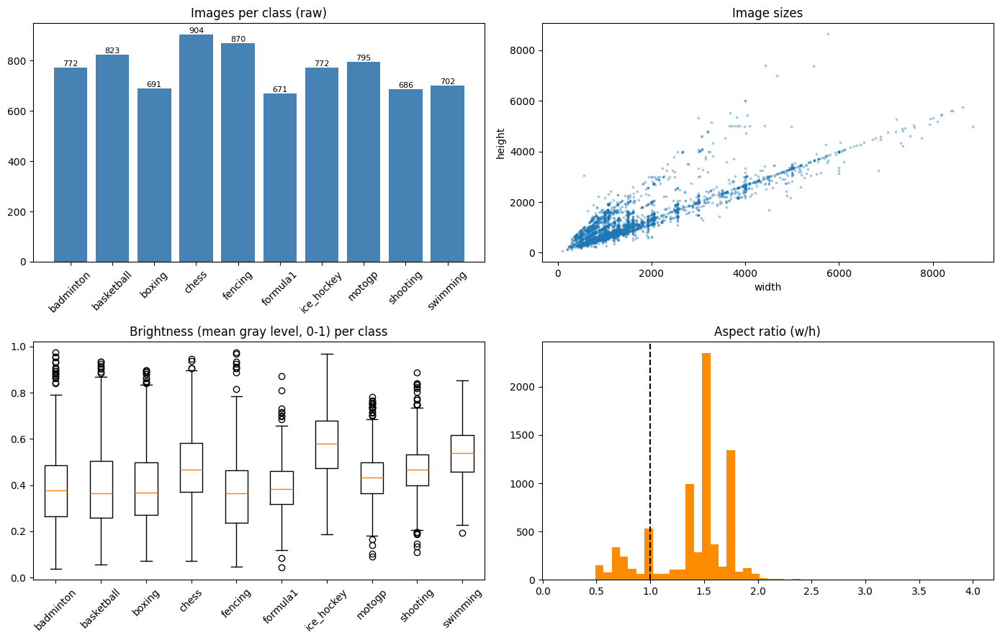

In [8]:
ok = df_raw[df_raw.ok].copy()
ok['is_gray'] = ok.is_gray.astype(bool)          # object dtype (None for unreadable rows) -> `~` would give -1/-2
ok['short_side'] = ok[['width', 'height']].min(axis=1)
ok['aspect'] = ok.width / ok.height

# ---- Table: per-class summary ----
eda = ok.groupby('label').agg(n_images=('path', 'count'),
                              mean_width=('width', 'mean'), mean_height=('height', 'mean'),
                              min_short_side=('short_side', 'min'),
                              pct_grayscale=('is_gray', lambda s: 100 * s.mean()),
                              brightness_mean=('brightness', 'mean'), brightness_sd=('brightness', 'std'),
                              contrast_mean=('contrast', 'mean')).reindex(CLASSES).round(3)
display(eda)
print("Image mode counts:\n", ok['mode'].value_counts().to_string())
print(f"\nColor images: {(~ok.is_gray).sum()} | Grayscale images: {ok.is_gray.sum()}")
print(f"Exact duplicate files (same MD5): {ok.md5.duplicated().sum()}")

# ---- Figures ----
fig, ax = plt.subplots(2, 2, figsize=(14, 9))
cnt = ok.label.value_counts().reindex(CLASSES)
ax[0, 0].bar(CLASSES, cnt.values, color='steelblue'); ax[0, 0].set_title('Images per class (raw)')
ax[0, 0].tick_params(axis='x', rotation=45)
for i, v in enumerate(cnt.values): ax[0, 0].text(i, v, str(v), ha='center', va='bottom', fontsize=8)
ax[0, 1].scatter(ok.width, ok.height, s=3, alpha=0.3); ax[0, 1].set_xlabel('width'); ax[0, 1].set_ylabel('height'); ax[0, 1].set_title('Image sizes')
ax[1, 0].boxplot([ok[ok.label == c].brightness for c in CLASSES]); ax[1, 0].set_xticklabels(CLASSES); ax[1, 0].set_title('Brightness (mean gray level, 0-1) per class')
ax[1, 0].tick_params(axis='x', rotation=45)
ax[1, 1].hist(ok.aspect, bins=50, color='darkorange'); ax[1, 1].axvline(1, color='k', ls='--'); ax[1, 1].set_title('Aspect ratio (w/h)')
plt.tight_layout(); savefig(fig, '1_eda'); plt.show()

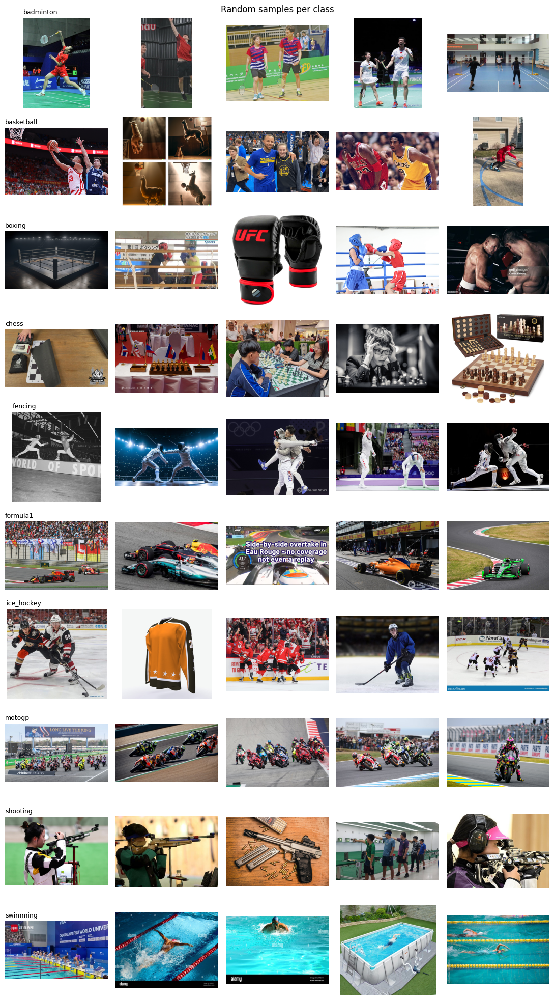

In [9]:
# Sample images per class (raw)
def show_samples(df, per_class=5, seed=0, title='Random samples per class'):
    rng = np.random.default_rng(seed)
    fig, axes = plt.subplots(K, per_class, figsize=(2.2 * per_class, 2.0 * K))
    for r, c in enumerate(CLASSES):
        sub = df[df.label == c]
        pick = rng.choice(len(sub), size=min(per_class, len(sub)), replace=False)
        for j in range(per_class):
            axes[r, j].axis('off')
            if j < len(pick):
                axes[r, j].imshow(Image.open(sub.iloc[pick[j]].path).convert('RGB'))
            if j == 0: axes[r, j].set_title(c, fontsize=9, loc='left')
    plt.suptitle(title); plt.tight_layout(); return fig

fig = show_samples(ok); savefig(fig, '1_samples'); plt.show()

## 1.4 Class imbalance check
Computed on the raw (readable) images; the ratio after cleaning is printed again in Section 2.2.

In [10]:
cnt = ok.label.value_counts().reindex(CLASSES)
ratio = cnt.max() / cnt.min()
print(cnt.to_string())
print(f"\nImbalance ratio (max/min) = {ratio:.2f}  (largest: {cnt.idxmax()}={cnt.max()}, smallest: {cnt.idxmin()}={cnt.min()})")
print("=> IMBALANCED" if ratio > 1.5 else "=> Approximately balanced")

label
badminton     772
basketball    823
boxing        691
chess         904
fencing       870
formula1      671
ice_hockey    772
motogp        795
shooting      686
swimming      702

Imbalance ratio (max/min) = 1.35  (largest: chess=904, smallest: formula1=671)
=> Approximately balanced


**Strategy for class imbalance (state it clearly in the slides):**
1. **Stratified split** — every split (train/val/test) keeps the same class proportions
2. **Class-weighted cross-entropy loss** — class weight $w_c = N / (K \cdot n_c)$, computed from the *train split only* (classes with fewer images get larger weights)
3. **Report imbalance-robust metrics** — Macro-F1, balanced accuracy and per-class precision/recall (in addition to accuracy)
4. Data augmentation is applied to the train set only (online)

> If the imbalance ratio ≈ 1, the class weights are ≈ 1 and have no effect on training.

# 2. Data preparation

## 2.1 Cleaning + offline preprocessing
Steps: (1) remove unreadable files → (2) remove images that are too small (short side < 64 px) → (3) remove exact duplicates (same MD5; if the same file appears in different classes, drop every copy because the labels conflict) → (4) *optional* (`REMOVE_NEAR_DUPLICATES = True`): remove near-duplicates (resized / re-encoded copies) found with a perceptual hash (dHash, Hamming distance ≤ `NEAR_DUP_MAX_DIST`), with the same rule for conflicting labels → (5) fix the EXIF orientation, convert to RGB, downscale so that the short side ≤ 512 px (keeping the aspect ratio) and save as JPEG for faster loading.

The cleaned images and `outputs/splits.csv` are reused on later runs (also after a kernel restart). Set `REBUILD_DATA = True` only when the raw dataset changes — this produces a new split and invalidates the cached results in `outputs/results.pkl`.

In [11]:
MIN_SIDE, MAX_SHORT_SIDE = 64, 512
SPLITS_FILE = OUT_DIR / 'splits.csv'

def dhash(path, size=8):
    # perceptual difference hash: 64 bits that barely change when an image is resized or re-encoded
    with Image.open(path) as im:
        g = ImageOps.exif_transpose(im).convert('L').resize((size + 1, size), Image.LANCZOS)
    a = np.asarray(g, dtype=np.int16)
    return np.packbits((a[:, 1:] > a[:, :-1]).ravel())

def near_duplicate_pairs(hashes, max_dist, chunk=256):
    # all pairs (i < j) whose dHash Hamming distance <= max_dist
    H = np.stack(hashes); out = []
    for s in range(0, len(H), chunk):
        d = np.unpackbits(np.bitwise_xor(H[s:s + chunk, None, :], H[None, :, :]), axis=2).sum(2)
        ii, jj = np.nonzero(d <= max_dist)
        keep = (ii + s) < jj
        out += [(int(i + s), int(j), int(d[i, j])) for i, j in zip(ii[keep], jj[keep])]
    return out

def _splits_ready():
    if not SPLITS_FILE.exists(): return False
    return bool(pd.read_csv(SPLITS_FILE).path.map(lambda p: Path(p).exists()).all())

DATA_READY = (not REBUILD_DATA) and _splits_ready()
if DATA_READY:
    print(f"Found {SPLITS_FILE} and all cleaned images -> cleaning and splitting are skipped "
          f"(set REBUILD_DATA = True to rebuild).")
else:
    if (OUT_DIR / 'results.pkl').exists():
        print(f"WARNING: rebuilding the dataset creates a new split -> {OUT_DIR / 'results.pkl'} and the checkpoints "
              f"no longer match it. Delete them before re-training.")
    report = {'raw': len(df_raw)}
    df = df_raw[df_raw.ok].copy();                                  report['after removing unreadable'] = len(df)
    df = df[df[['width', 'height']].min(axis=1) >= MIN_SIDE];       report[f'after removing short_side<{MIN_SIDE}'] = len(df)
    n_labels = df.groupby('md5').label.nunique()
    df = df[~df.md5.isin(n_labels[n_labels > 1].index)];            report['after removing cross-class duplicates'] = len(df)
    df = df.drop_duplicates('md5', keep='first').reset_index(drop=True); report['after removing exact duplicates'] = len(df)

    if REMOVE_NEAR_DUPLICATES:
        hs = [dhash(p) for p in tqdm(df.path, desc='dHash')]
        parent = list(range(len(df)))
        def _root(i):
            while parent[i] != i:
                parent[i] = parent[parent[i]]; i = parent[i]
            return i
        for i, j, _ in near_duplicate_pairs(hs, NEAR_DUP_MAX_DIST):
            parent[_root(i)] = _root(j)
        df['grp'] = [_root(i) for i in range(len(df))]
        n_lab = df.groupby('grp').label.nunique()
        df = df[~df.grp.isin(n_lab[n_lab > 1].index)];              report['after removing cross-class near-duplicates'] = len(df)
        df = df.drop_duplicates('grp', keep='first').drop(columns='grp'); report['after removing near-duplicates'] = len(df)
    print(json.dumps(report, indent=2))

    shutil.rmtree(CLEAN_DIR, ignore_errors=True)
    new_paths = []
    for i, row in enumerate(tqdm(df.itertuples(), total=len(df), desc='Resize+save')):
        im = ImageOps.exif_transpose(Image.open(row.path)).convert('RGB')
        w, h = im.size; s = min(w, h)
        if s > MAX_SHORT_SIDE:
            f = MAX_SHORT_SIDE / s
            im = im.resize((round(w * f), round(h * f)), Image.BICUBIC)
        out = CLEAN_DIR / row.label / f'{i:05d}.jpg'
        out.parent.mkdir(parents=True, exist_ok=True)
        im.save(out, quality=95)
        new_paths.append(str(out))

    df_clean = pd.DataFrame({'path': new_paths, 'label': df.label.values})
    df_clean['y'] = df_clean.label.map(class_to_idx)
    print("\nClean dataset:", len(df_clean), "images")
    print(df_clean.label.value_counts().reindex(CLASSES).to_string())

{
  "raw": 7686,
  "after removing unreadable": 7686,
  "after removing short_side<64": 7686,
  "after removing cross-class duplicates": 7686,
  "after removing exact duplicates": 7677
}


Resize+save:  12%|█▏        | 938/7677 [00:10<01:49, 61.37it/s] /Users/administrator/Library/Python/3.9/lib/python/site-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
Resize+save: 100%|██████████| 7677/7677 [01:36<00:00, 79.17it/s] 


Clean dataset: 7677 images
label
badminton     771
basketball    817
boxing        691
chess         904
fencing       870
formula1      671
ice_hockey    770
motogp        795
shooting      686
swimming      702


## 2.2 Train / Validation / Test split
- **Stratified random split 70 / 15 / 15** (`random_state=42`) — class proportions are preserved in every split, and the **same split is used for every architecture and seed**, so the variation between runs comes only from training randomness (initial weights, batch order, augmentation).
- **The test set is used only for the final evaluation** — validation is used to choose the hyperparameters, the best epoch and the strategy.
- The split is always re-loaded from `outputs/splits.csv`, so the row order of `test_df` always matches the predictions cached in `results.pkl`.

In [12]:
if not DATA_READY:
    train_df, tmp_df = train_test_split(df_clean, test_size=0.30, stratify=df_clean.y, random_state=SPLIT_SEED)
    val_df, test_df  = train_test_split(tmp_df,  test_size=0.50, stratify=tmp_df.y,  random_state=SPLIT_SEED)
    pd.concat([train_df.assign(split='train'), val_df.assign(split='val'), test_df.assign(split='test')]).to_csv(SPLITS_FILE, index=False)

# always (re)load from disk -> identical row order after a kernel restart (test_df must match the cached predictions)
splits = pd.read_csv(SPLITS_FILE)
assert set(splits.label) <= set(CLASSES) and (splits.label.map(class_to_idx) == splits.y).all(), "splits.csv does not match CLASSES"
train_df, val_df, test_df = [splits[splits.split == s].drop(columns='split').reset_index(drop=True) for s in ('train', 'val', 'test')]
df_clean = splits.drop(columns='split')

split_tbl = pd.DataFrame({'train': train_df.label.value_counts(), 'val': val_df.label.value_counts(),
                          'test': test_df.label.value_counts()}).reindex(CLASSES).fillna(0).astype(int)
split_tbl['total'] = split_tbl.sum(axis=1)
split_tbl.loc['TOTAL'] = split_tbl.sum()
display(split_tbl)
print("Class proportion (%) per split — should be nearly identical:")
display((pd.DataFrame({n: d.label.value_counts(normalize=True) * 100 for n, d in
        [('train', train_df), ('val', val_df), ('test', test_df)]}).reindex(CLASSES)).round(2))

# No leakage between splits (same file)
assert not (set(train_df.path) & set(val_df.path)) and not (set(train_df.path) & set(test_df.path)) and not (set(val_df.path) & set(test_df.path))
print("No sample overlap between train / val / test.")
cnt_c = df_clean.label.value_counts().reindex(CLASSES)
print(f"Imbalance ratio after cleaning (max/min) = {cnt_c.max() / cnt_c.min():.2f}  "
      f"(largest: {cnt_c.idxmax()}={cnt_c.max()}, smallest: {cnt_c.idxmin()}={cnt_c.min()})")

# Class weights (from the TRAIN split only) for the weighted cross-entropy
counts = train_df.y.value_counts().reindex(range(K), fill_value=0).values
assert (counts > 0).all(), "every class needs at least one training image"
class_weights = torch.tensor(counts.sum() / (K * counts), dtype=torch.float32)
CLASS_W_DEV = class_weights.to(device)
print("\nClass weights:", {c: round(float(w), 3) for c, w in zip(CLASSES, class_weights)})

,train,val,test,total
label,,,,
badminton,539,116,116,771
basketball,572,123,122,817
boxing,484,104,103,691
chess,633,135,136,904
fencing,609,130,131,870
formula1,470,100,101,671
ice_hockey,539,116,115,770
motogp,556,119,120,795
shooting,480,103,103,686


Class proportion (%) per split — should be nearly identical:


,train,val,test
label,,,
badminton,10.03,10.07,10.07
basketball,10.65,10.68,10.59
boxing,9.01,9.03,8.94
chess,11.78,11.72,11.81
fencing,11.33,11.28,11.37
formula1,8.75,8.68,8.77
ice_hockey,10.03,10.07,9.98
motogp,10.35,10.33,10.42
shooting,8.93,8.94,8.94


No sample overlap between train / val / test.
Imbalance ratio after cleaning (max/min) = 1.35  (largest: chess=904, smallest: formula1=671)

Class weights: {'badminton': 0.997, 'basketball': 0.939, 'boxing': 1.11, 'chess': 0.849, 'fencing': 0.882, 'formula1': 1.143, 'ice_hockey': 0.997, 'motogp': 0.966, 'shooting': 1.119, 'swimming': 1.094}


### Near-duplicate leakage check (perceptual hash)
MD5 only catches byte-identical files. Web-scraped datasets often contain the same photo resized or re-encoded; if such copies end up in different splits, the test score is too optimistic. This cell compares the dHash of every cleaned image and lists the near-duplicate pairs that fall in **different splits** (saved to `outputs/near_duplicate_leaks.csv`). If any are found, either set `REMOVE_NEAR_DUPLICATES = True` and `REBUILD_DATA = True` and re-run from Section 2.1 (then re-train), or report them as a limitation.

dHash (leak check): 100%|██████████| 7677/7677 [00:12<00:00, 606.36it/s]


Near-duplicate pairs (dHash distance <= 4): 18 in total, 4 across different splits
  involving the test set: 1 | with conflicting labels: 0
  -> fix: REMOVE_NEAR_DUPLICATES = True and REBUILD_DATA = True, then re-run from Section 2.1 and re-train


,path_a,split_a,label_a,path_b,split_b,label_b,hamming
0,sport_clean/badminton/00660.jpg,train,badminton,sport_clean/badminton/00679.jpg,val,badminton,1
1,sport_clean/swimming/07318.jpg,train,swimming,sport_clean/swimming/07395.jpg,val,swimming,4
2,sport_clean/boxing/01805.jpg,train,boxing,sport_clean/boxing/01814.jpg,test,boxing,4
3,sport_clean/basketball/00919.jpg,train,basketball,sport_clean/basketball/00881.jpg,val,basketball,1


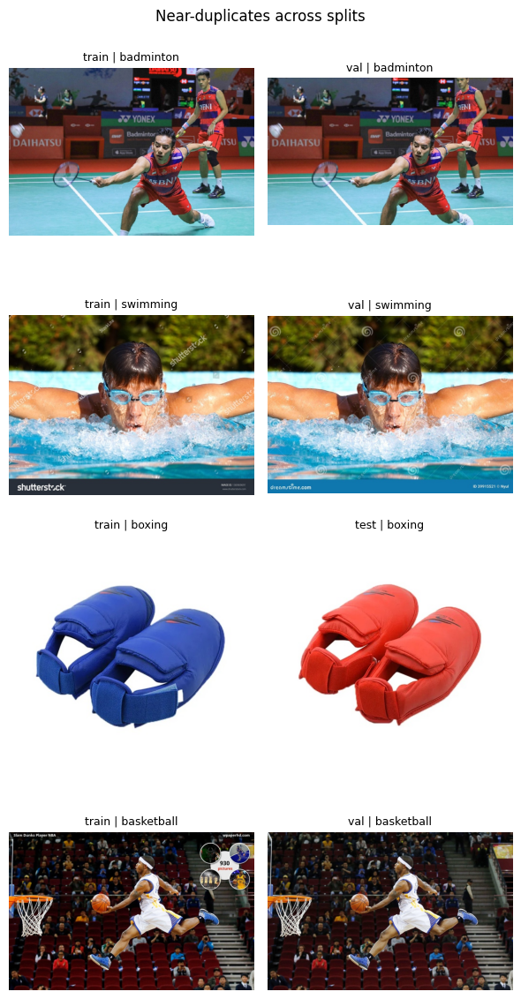

In [13]:
hs = [dhash(p) for p in tqdm(splits.path, desc='dHash (leak check)')]
pairs = near_duplicate_pairs(hs, NEAR_DUP_MAX_DIST)
LEAK_COLS = ['path_a', 'split_a', 'label_a', 'path_b', 'split_b', 'label_b', 'hamming']
leak = pd.DataFrame([(splits.path[i], splits.split[i], splits.label[i], splits.path[j], splits.split[j], splits.label[j], d)
                     for i, j, d in pairs if splits.split[i] != splits.split[j]], columns=LEAK_COLS)
leak.to_csv(OUT_DIR / 'near_duplicate_leaks.csv', index=False)
print(f"Near-duplicate pairs (dHash distance <= {NEAR_DUP_MAX_DIST}): {len(pairs)} in total, {len(leak)} across different splits")
if len(leak):
    print(f"  involving the test set: {((leak.split_a == 'test') | (leak.split_b == 'test')).sum()} | "
          f"with conflicting labels: {(leak.label_a != leak.label_b).sum()}")
    print("  -> fix: REMOVE_NEAR_DUPLICATES = True and REBUILD_DATA = True, then re-run from Section 2.1 and re-train")
    display(leak.head(10))
    k = min(5, len(leak)); fig, axes = plt.subplots(k, 2, figsize=(6, 3 * k), squeeze=False)
    for r, row in enumerate(leak.head(k).itertuples()):
        for c, (p, s, l) in enumerate([(row.path_a, row.split_a, row.label_a), (row.path_b, row.split_b, row.label_b)]):
            axes[r, c].imshow(Image.open(p).convert('RGB')); axes[r, c].set_title(f"{s} | {l}", fontsize=9); axes[r, c].axis('off')
    plt.suptitle('Near-duplicates across splits'); plt.tight_layout(); savefig(fig, '2_near_duplicates'); plt.show()
else:
    print("No near-duplicate leakage between splits.")

## 2.3 Transforms and data augmentation (online)
| | Train | Val / Test |
|---|---|---|
| Geometry | `RandomResizedCrop(224, scale=(0.5,1))`, `RandomHorizontalFlip(0.5)`, `RandomRotation(±10°)` | `Resize(256)` → `CenterCrop(224)` |
| Photometric | `ColorJitter(brightness .3, contrast .3, saturation .2, hue .02)` | — |
| Normalization | ImageNet mean/std (must match the statistics the backbones were pre-trained with) | same |

Rationale: sport photos vary in camera angle, zoom and lighting, so we use scale crops, horizontal flips, small rotations and colour/brightness jitter. Large rotations and vertical flips are not used because they produce unnatural images.

In [14]:
_w = {a: getattr(torchvision.models, n).IMAGENET1K_V2.transforms() if a != 'vgg16'
      else torchvision.models.VGG16_Weights.IMAGENET1K_V1.transforms()
      for a, n in [('vgg16', ''), ('resnet50', 'ResNet50_Weights'), ('mobilenet_v2', 'MobileNet_V2_Weights')]}
assert all(list(t.mean) == list(_w['vgg16'].mean) and list(t.std) == list(_w['vgg16'].std) for t in _w.values())
IMAGENET_MEAN, IMAGENET_STD = list(_w['vgg16'].mean), list(_w['vgg16'].std)
print(f"ImageNet normalization: mean={IMAGENET_MEAN}, std={IMAGENET_STD}")

ImageNet normalization: mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]


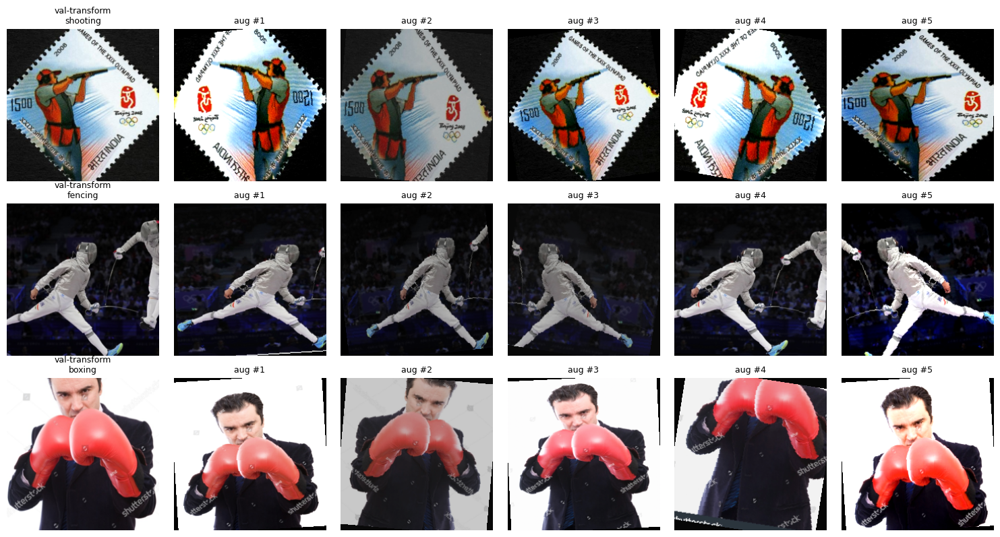

In [15]:
# IMAGENET_MEAN, IMAGENET_STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

train_transform = T.Compose([
    T.ToImage(),
    T.RandomResizedCrop(IMG_SIZE, scale=(0.5, 1.0), ratio=(3/4, 4/3), antialias=True),
    T.RandomHorizontalFlip(p=0.5),
    T.RandomRotation(degrees=10),
    T.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.2, hue=0.02),
    T.ToDtype(torch.float32, scale=True),
    T.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])
val_transform = T.Compose([          # also used for the test set (no random augmentation)
    T.ToImage(),
    T.Resize(256, antialias=True),
    T.CenterCrop(IMG_SIZE),
    T.ToDtype(torch.float32, scale=True),
    T.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

class SportDataset(torch.utils.data.Dataset):
    def __init__(self, df, transform):
        self.paths, self.labels, self.transform = df.path.tolist(), df.y.tolist(), transform
    def __len__(self): return len(self.paths)
    def __getitem__(self, i):
        return self.transform(Image.open(self.paths[i]).convert('RGB')), self.labels[i]

def make_loader(df, transform, batch_size, shuffle, seed=0):
    g = torch.Generator().manual_seed(seed)
    return torch.utils.data.DataLoader(SportDataset(df, transform), batch_size=batch_size, shuffle=shuffle,
                                       num_workers=NUM_WORKERS, pin_memory=(device.type == 'cuda'), generator=g)

def make_loaders(batch_size, seed=0):
    return (make_loader(train_df, train_transform, batch_size, True, seed),
            make_loader(val_df, val_transform, batch_size, False),
            make_loader(test_df, val_transform, batch_size, False))

def denorm(t):
    m, s = torch.tensor(IMAGENET_MEAN)[:, None, None], torch.tensor(IMAGENET_STD)[:, None, None]
    return (t * s + m).clamp(0, 1).permute(1, 2, 0).numpy()

# Visualize augmentation: same training image, 5 random draws vs. val transform
ds_aug = SportDataset(train_df, train_transform); ds_val = SportDataset(train_df, val_transform)
fig, axes = plt.subplots(3, 6, figsize=(15, 8))
for r, idx in enumerate([0, len(train_df) // 2, len(train_df) - 1]):
    axes[r, 0].imshow(denorm(ds_val[idx][0])); axes[r, 0].set_title(f'val-transform\n{CLASSES[ds_val[idx][1]]}', fontsize=9)
    for j in range(1, 6):
        axes[r, j].imshow(denorm(ds_aug[idx][0])); axes[r, j].set_title(f'aug #{j}', fontsize=9)
for a in axes.ravel(): a.axis('off')
plt.tight_layout(); savefig(fig, '2_augmentation'); plt.show()

# 3. Model architecture

## 3.1 Chosen CNN backbones (substantially different designs)
| Backbone | Key idea | Why chosen |
|---|---|---|
| **VGG16** | Plain stack of 3×3 convs (13 conv layers), ~138M params (mostly in the FC head) | Classic baseline with straightforward features; the model used for Grad-CAM in class |
| **ResNet50** | Residual (skip) connections + bottleneck blocks, ~25M params | Deep yet easy to train; represents the "high-accuracy" standard CNNs |
| **MobileNetV2** | Depthwise-separable convs + inverted residuals, ~3.5M params | Light and fast; suitable for deployment on resource-constrained devices |

## 3.2 Pre-trained (ImageNet) models on our images — *before* any training

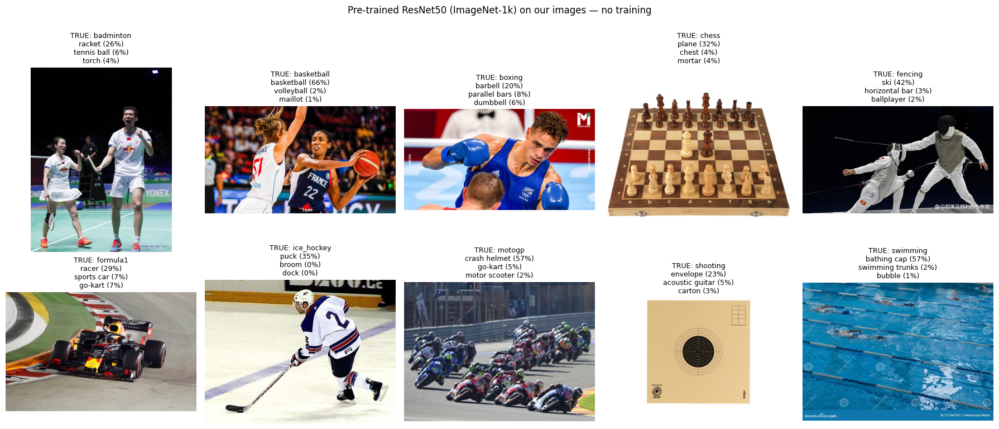

,vgg16,mobilenet_v2,resnet50
true class,,,
badminton,"racket (7/10), maze (1/10)","racket (5/10), volleyball (2/10)","racket (5/10), basketball (2/10)"
basketball,"basketball (7/10), racket (1/10)","basketball (5/10), tricycle (1/10)","basketball (9/10), rugby ball (1/10)"
boxing,"stage (3/10), suspension bridge (2/10)","pier (2/10), theater curtain (1/10)","stage (5/10), punching bag (1/10)"
chess,"perfume (2/10), honeycomb (1/10)","abacus (2/10), apiary (1/10)","candle (2/10), dumbbell (1/10)"
fencing,"ballplayer (3/10), racket (1/10)","horizontal bar (2/10), ballplayer (2/10)","ballplayer (7/10), horizontal bar (1/10)"
formula1,"racer (8/10), sports car (1/10)","racer (6/10), go-kart (3/10)","racer (7/10), go-kart (3/10)"
ice_hockey,"puck (9/10), basketball (1/10)","puck (5/10), football helmet (1/10)","puck (8/10), stretcher (1/10)"
motogp,crash helmet (10/10),"crash helmet (8/10), go-kart (2/10)","crash helmet (9/10), go-kart (1/10)"
shooting,"rifle (4/10), ballplayer (1/10)","rifle (4/10), assault rifle (1/10)","rifle (4/10), revolver (2/10)"


In [16]:
PRE_BUILD   = {'vgg16': torchvision.models.vgg16, 'mobilenet_v2': torchvision.models.mobilenet_v2, 'resnet50': torchvision.models.resnet50}
PRE_WEIGHTS = {'vgg16': torchvision.models.VGG16_Weights.IMAGENET1K_V1,
               'mobilenet_v2': torchvision.models.MobileNet_V2_Weights.IMAGENET1K_V2,
               'resnet50': torchvision.models.ResNet50_Weights.IMAGENET1K_V2}
PRETRAINED = {}   # cache of the ORIGINAL 1000-class models

def get_pretrained(arch):
    if arch not in PRETRAINED:
        PRETRAINED[arch] = PRE_BUILD[arch](weights=PRE_WEIGHTS[arch]).to(device).eval()
    return PRETRAINED[arch]

@torch.inference_mode()
def imagenet_topk(arch, pil, k=3):
    x = val_transform(pil.convert('RGB')).unsqueeze(0).to(device)
    p = F.softmax(get_pretrained(arch)(x), dim=1)[0]
    pr, idx = p.topk(k)
    cats = PRE_WEIGHTS[arch].meta['categories']
    return [(cats[i], float(v)) for v, i in zip(pr.cpu(), idx.cpu())]

# ---- (a) One example per class: top-3 ImageNet predictions of ResNet50 ----
demo = train_df.groupby('label').sample(1, random_state=0).set_index('label').loc[CLASSES]
fig, axes = plt.subplots(2, 5, figsize=(18, 8))
for ax, (c, row) in zip(axes.ravel(), demo.iterrows()):
    im = Image.open(row.path).convert('RGB'); top = imagenet_topk('resnet50', im, 3)
    ax.imshow(im); ax.axis('off')
    ax.set_title(f"TRUE: {c}\n" + "\n".join(f"{n[:22]} ({p*100:.0f}%)" for n, p in top), fontsize=9)
plt.suptitle('Pre-trained ResNet50 (ImageNet-1k) on our images — no training', y=1.0); plt.tight_layout()
savefig(fig, '3_pretrained_resnet50'); plt.show()

# ---- (b) Most frequent ImageNet top-1 label per class (10 images/class) for all 3 backbones ----
rows = []
for c in CLASSES:
    sub = train_df[train_df.label == c].sample(min(10, (train_df.label == c).sum()), random_state=0)
    ims = [Image.open(p).convert('RGB') for p in sub.path]
    row = {'true class': c}
    for arch in ARCHS:
        tops = Counter(imagenet_topk(arch, im, 1)[0][0] for im in ims).most_common(2)
        row[arch] = ", ".join(f"{n} ({k}/{len(ims)})" for n, k in tops)
    rows.append(row)
pd.set_option('display.max_colwidth', 80)
display(pd.DataFrame(rows).set_index('true class'))

> ✏️ **Summary for the slides:** check in the table above whether the pre-trained CNNs spread their predictions over other ImageNet classes (e.g. `racket`, `puck`, `scuba_diver`, `ballplayer`) and that no output corresponds directly to our 10 sport classes → the classifier has to be replaced and fine-tuned.
> *(Note: some classes, e.g. basketball, have a closely related ImageNet label — state explicitly in the slides in what way such predictions are "partly right / not specific enough".)*

## 3.3 Modified architectures (backbone cut + new classifier head)

| Backbone | Kept (ImageNet weights) | Removed | Added (new head) | Last block (unfrozen in `last_block`) |
|---|---|---|---|---|
| VGG16 | `features` (13 conv) + `avgpool` → 25,088-d | original `classifier` (FC 4096→4096→1000) | `Linear(25088,H)→ReLU→Dropout(p)→Linear(H,10)` | `features[24:]` (conv block 5) |
| ResNet50 | conv1 … layer4 + avgpool → 2,048-d | original `fc` (2048→1000) | `Linear(2048,H)→ReLU→Dropout(p)→Linear(H,10)` | `layer4` |
| MobileNetV2 | `features` + global avgpool → 1,280-d | original `classifier` (Dropout+Linear 1280→1000) | `Linear(1280,H)→ReLU→Dropout(p)→Linear(H,10)` | `features[14:]` |

The **same head structure** is used for all 3 backbones so that only the backbones differ; the hidden size `H` and the dropout `p` are hyperparameters searched by the W&B Sweep.

In [17]:
IN_FEATURES = {'vgg16': 25088, 'resnet50': 2048, 'mobilenet_v2': 1280}

def get_head(m, arch):       return m.fc if arch == 'resnet50' else m.classifier
# def get_last_block(m, arch): return {'vgg16': m.features[24:], 'resnet50': m.layer4, 'mobilenet_v2': m.features[14:]}[arch]
def get_last_block(m, arch):
    return {'vgg16': lambda: m.features[24:], 'resnet50': lambda: m.layer4, 'mobilenet_v2': lambda: m.features[14:]}[arch]()

def set_trainable(m, arch, strategy):
    # strategy 'frozen'     : transfer learning  -> only the new head is trained
    # strategy 'last_block' : fine-tuning        -> new head + last backbone block are trained
    for p in m.parameters(): p.requires_grad = False
    for p in get_head(m, arch).parameters(): p.requires_grad = True
    if strategy == 'last_block':
        for p in get_last_block(m, arch).parameters(): p.requires_grad = True

def build_model(arch, hidden=512, dropout=0.5, strategy='frozen', num_classes=K, pretrained=True):
    m = PRE_BUILD[arch](weights=PRE_WEIGHTS[arch] if pretrained else None)
    head = nn.Sequential(nn.Linear(IN_FEATURES[arch], hidden), nn.ReLU(inplace=True),
                         nn.Dropout(dropout), nn.Linear(hidden, num_classes))
    if arch == 'resnet50': m.fc = head
    else:                  m.classifier = head
    set_trainable(m, arch, strategy)
    return m

def count_params(m):
    return sum(p.numel() for p in m.parameters()), sum(p.numel() for p in m.parameters() if p.requires_grad)

for arch in ARCHS:
    m = build_model(arch, hidden=512, dropout=0.5, strategy='last_block', pretrained=False)
    tot, tr = count_params(m)
    print(f"\n{'='*20} {arch}: total {tot/1e6:.2f}M params | trainable (last_block strategy) {tr/1e6:.2f}M {'='*20}")
    print("New head:", get_head(m, arch))
    torchinfo.summary(m, input_size=(1, 3, IMG_SIZE, IMG_SIZE), depth=2, col_names=("output_size", "num_params", "trainable"), verbose=1)


==================== vgg16: total 27.57M params | trainable (last_block strategy) 19.93M ====================
New head: Sequential(
  (0): Linear(in_features=25088, out_features=512, bias=True)
  (1): ReLU(inplace=True)
  (2): Dropout(p=0.5, inplace=False)
  (3): Linear(in_features=512, out_features=10, bias=True)
)
Layer (type:depth-idx)                   Output Shape              Param #                   Trainable
VGG                                      [1, 10]                   --                        Partial
├─Sequential: 1-1                        [1, 512, 7, 7]            --                        Partial
│    └─Conv2d: 2-1                       [1, 64, 224, 224]         (1,792)                   False
│    └─ReLU: 2-2                         [1, 64, 224, 224]         --                        --
│    └─Conv2d: 2-3                       [1, 64, 224, 224]         (36,928)                  False
│    └─ReLU: 2-4                         [1, 64, 224, 224]         --             

## 3.4 Network diagram (pre-trained backbone + fine-tuning + new head)

The diagram shows the **frozen** part (grey, ImageNet weights), the **unfrozen last block** (orange, red frame) and the **new head** (blue) of each backbone for a 3×224×224 input. `H` and `p` are chosen by the W&B Sweep (Section 4.2), so they are drawn symbolically here.

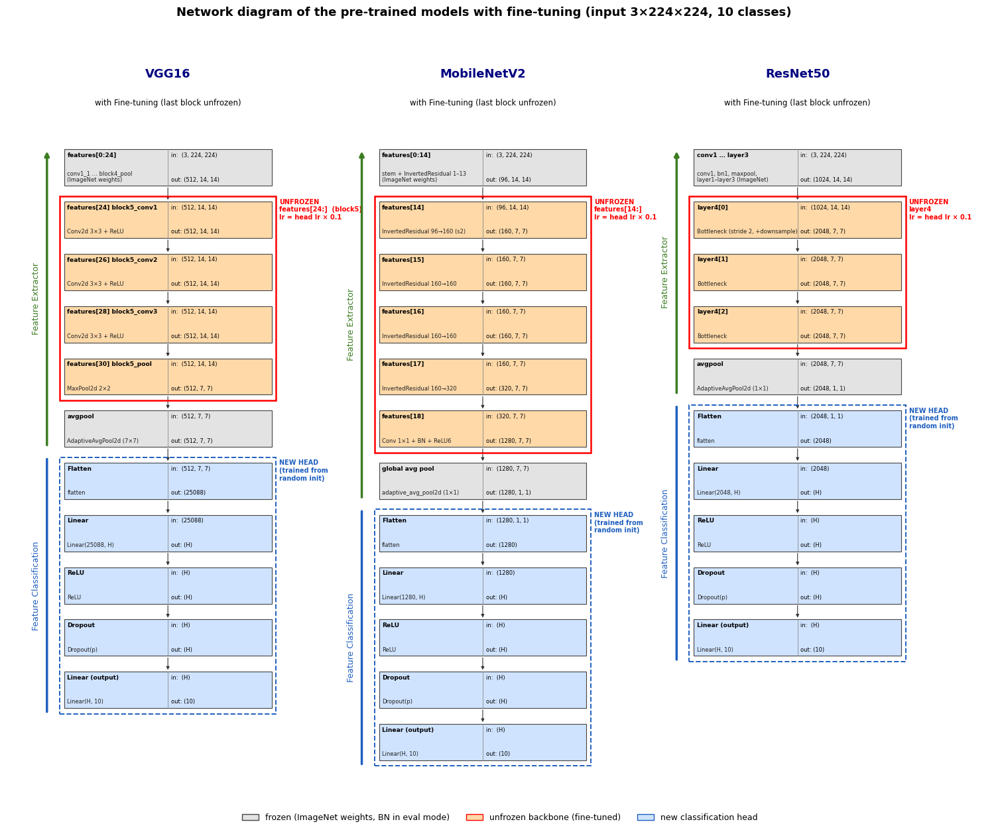

In [18]:
# 3.4 Network diagram of the pre-trained models with fine-tuning
# Draws, for each architecture: frozen backbone (grey) -> unfrozen last block (orange, red frame, only if strategy='last_block')
# -> new classification head (blue). Shapes are for a 224x224 input (torchvision implementations).
# Needs: ARCHS, CLASSES, plt, savefig, build_model, count_params (BACKBONE_LR_MULT is optional).
# H and p are tuned later (Section 4.2), so they are drawn symbolically; call plot_network_diagram(ARCHS, BEST_CFG) after Section 6.1
# to draw the final values instead.
from matplotlib.patches import Rectangle, FancyArrowPatch

_S = lambda t: '(' + ', '.join(map(str, t)) + ')'
ARCH_SPEC = {
    'vgg16': dict(
        title='VGG16', in_feat=25088, ft_label='features[24:]  (block5)',
        frozen=('features[0:24]', 'conv1_1 … block4_pool\n(ImageNet weights)', (3, 224, 224), (512, 14, 14)),
        ft=[('features[24] block5_conv1', 'Conv2d 3×3 + ReLU', (512, 14, 14), (512, 14, 14)),
            ('features[26] block5_conv2', 'Conv2d 3×3 + ReLU', (512, 14, 14), (512, 14, 14)),
            ('features[28] block5_conv3', 'Conv2d 3×3 + ReLU', (512, 14, 14), (512, 14, 14)),
            ('features[30] block5_pool', 'MaxPool2d 2×2', (512, 14, 14), (512, 7, 7))],
        pool=('avgpool', 'AdaptiveAvgPool2d (7×7)', (512, 7, 7), (512, 7, 7)), flat_in=(512, 7, 7)),
    'resnet50': dict(
        title='ResNet50', in_feat=2048, ft_label='layer4',
        frozen=('conv1 … layer3', 'conv1, bn1, maxpool,\nlayer1–layer3 (ImageNet)', (3, 224, 224), (1024, 14, 14)),
        ft=[('layer4[0]', 'Bottleneck (stride 2, +downsample)', (1024, 14, 14), (2048, 7, 7)),
            ('layer4[1]', 'Bottleneck', (2048, 7, 7), (2048, 7, 7)),
            ('layer4[2]', 'Bottleneck', (2048, 7, 7), (2048, 7, 7))],
        pool=('avgpool', 'AdaptiveAvgPool2d (1×1)', (2048, 7, 7), (2048, 1, 1)), flat_in=(2048, 1, 1)),
    'mobilenet_v2': dict(
        title='MobileNetV2', in_feat=1280, ft_label='features[14:]',
        frozen=('features[0:14]', 'stem + InvertedResidual 1–13\n(ImageNet weights)', (3, 224, 224), (96, 14, 14)),
        ft=[('features[14]', 'InvertedResidual 96→160 (s2)', (96, 14, 14), (160, 7, 7)),
            ('features[15]', 'InvertedResidual 160→160', (160, 7, 7), (160, 7, 7)),
            ('features[16]', 'InvertedResidual 160→160', (160, 7, 7), (160, 7, 7)),
            ('features[17]', 'InvertedResidual 160→320', (160, 7, 7), (320, 7, 7)),
            ('features[18]', 'Conv 1×1 + BN + ReLU6', (320, 7, 7), (1280, 7, 7))],
        pool=('global avg pool', 'adaptive_avg_pool2d (1×1)', (1280, 7, 7), (1280, 1, 1)), flat_in=(1280, 1, 1)),
}

BW, BH, GAP = 5.4, 0.78, 0.34          # box width / height / vertical gap
C_FROZEN, C_TRAIN, C_HEAD = '#e3e3e3', '#ffd9a8', '#cfe3ff'

def _box(ax, x, y, name, typ, shp_in, shp_out, fc, ec='#444', lw=0.8):
    ax.add_patch(Rectangle((x, y - BH), BW, BH, fc=fc, ec=ec, lw=lw))
    ax.plot([x + BW * 0.5] * 2, [y - BH, y], c='#888', lw=0.6)
    ax.text(x + 0.08, y - 0.06, name, fontsize=6.6, va='top', ha='left', weight='bold')
    ax.text(x + 0.08, y - BH + 0.07, typ, fontsize=6.0, va='bottom', ha='left', color='#222', linespacing=0.95)
    ax.text(x + BW * 0.5 + 0.08, y - 0.06, f"in:  {_S(shp_in)}" if shp_in is not None else '', fontsize=6.0, va='top', ha='left')
    ax.text(x + BW * 0.5 + 0.08, y - BH + 0.07, f"out: {_S(shp_out)}" if shp_out is not None else '', fontsize=6.0, va='bottom', ha='left')

def _arrow(ax, x, y_from, y_to):
    ax.add_patch(FancyArrowPatch((x + BW / 2, y_from), (x + BW / 2, y_to), arrowstyle='-|>', mutation_scale=7, lw=0.8, color='#333'))

def draw_arch(ax, arch, cfg, x0=0.0, params=None):
    sp, n_cls = ARCH_SPEC[arch], (len(CLASSES) if 'CLASSES' in globals() else 10)
    H, p, strat = cfg['hidden'], cfg['dropout'], cfg['strategy']
    mult = globals().get('BACKBONE_LR_MULT', 0.1)
    ft = strat == 'last_block'
    y = 0.0
    ax.text(x0 + BW / 2, y + 1.55, sp['title'], ha='center', fontsize=13, weight='bold', color='navy')
    ax.text(x0 + BW / 2, y + 0.95, f"{'with Fine-tuning (last block unfrozen)' if ft else 'frozen backbone (feature extractor only)'}",
            ha='center', fontsize=8.5)
    y_top = y
    # --- frozen part ---
    n, t, i, o = sp['frozen']; _box(ax, x0, y, n, t, i, o, C_FROZEN); y -= BH + GAP; _arrow(ax, x0, y + GAP, y)
    # --- last block (unfrozen or still frozen) ---
    y_ft_top = y + 0.12
    for k, (n, t, i, o) in enumerate(sp['ft']):
        _box(ax, x0, y, n, t, i, o, C_TRAIN if ft else C_FROZEN); y -= BH + GAP; _arrow(ax, x0, y + GAP, y)
    y_ft_bot = y + GAP - 0.12                            # frame ends below the last block with weights
    n, t, i, o = sp['pool']; _box(ax, x0, y, n, t, i, o, C_FROZEN)
    y_feat_end = y - BH; y -= BH + GAP
    if ft:
        ax.add_patch(Rectangle((x0 - 0.12, y_ft_bot), BW + 0.24, y_ft_top - y_ft_bot, fc='none', ec='red', lw=1.8))
        ax.text(x0 + BW + 0.2, y_ft_top - 0.05, f"UNFROZEN\n{sp['ft_label']}\nlr = head lr × {mult:g}", color='red', fontsize=7,
                va='top', ha='left', weight='bold')
    # --- head ---
    _arrow(ax, x0, y + GAP, y)
    y_head_top = y + 0.12
    head = [('Flatten', 'flatten', sp['flat_in'], (sp['in_feat'],)),
            ('Linear', f"Linear({sp['in_feat']}, {H})", (sp['in_feat'],), (H,)),
            ('ReLU', 'ReLU', (H,), (H,)),
            ('Dropout', (f'Dropout(p={p})' if not isinstance(p, str) else f'Dropout({p})'), (H,), (H,)),
            ('Linear (output)', f'Linear({H}, {n_cls})', (H,), (n_cls,))]
    for k, (n, t, i, o) in enumerate(head):
        _box(ax, x0, y, n, t, i, o, C_HEAD)
        if k < len(head) - 1: y -= BH + GAP; _arrow(ax, x0, y + GAP, y)
    y_head_bot = y - BH - 0.12
    ax.add_patch(Rectangle((x0 - 0.12, y_head_bot), BW + 0.24, y_head_top - y_head_bot, fc='none', ec='#1f5fbf', lw=1.4, ls='--'))
    ax.text(x0 + BW + 0.2, y_head_top - 0.05, 'NEW HEAD\n(trained from\nrandom init)', color='#1f5fbf', fontsize=7, va='top', ha='left', weight='bold')
    # side arrows like the reference figure
    ax.annotate('', xy=(x0 - 0.45, y_top), xytext=(x0 - 0.45, y_feat_end), arrowprops=dict(arrowstyle='-|>', color='#3b7d23', lw=2.5))
    ax.text(x0 - 0.62, (y_top + y_feat_end) / 2, 'Feature Extractor', rotation=90, va='center', ha='right', color='#3b7d23', fontsize=9)
    ax.annotate('', xy=(x0 - 0.45, y_head_bot), xytext=(x0 - 0.45, y_head_top), arrowprops=dict(arrowstyle='-', color='#1f5fbf', lw=2.5))
    ax.text(x0 - 0.62, (y_head_top + y_head_bot) / 2, 'Feature Classification', rotation=90, va='center', ha='right', color='#1f5fbf', fontsize=9)
    if params:
        ax.text(x0 + BW / 2, y_head_bot - 0.5, f"Total {params[0]/1e6:.1f} M params | trainable {params[1]/1e6:.1f} M",
                ha='center', fontsize=8, style='italic')
    return y_head_bot

def plot_network_diagram(archs, cfgs, name='3_network_diagram'):
    P = {}
    for a in archs:                                  # parameter counts (only when hidden/dropout are numbers)
        try:
            assert not isinstance(cfgs[a]['hidden'], str)
            m = build_model(a, cfgs[a]['hidden'], cfgs[a]['dropout'], cfgs[a]['strategy'], pretrained=False)
            P[a] = count_params(m); del m
        except Exception:
            P[a] = None
    fig, ax = plt.subplots(figsize=(6.4 * len(archs), 15))
    ymin = 0
    for k, a in enumerate(archs):
        ymin = min(ymin, draw_arch(ax, a, cfgs[a], x0=k * 8.2 + 1.0, params=P[a]))
    ax.set_xlim(-0.5, 8.2 * len(archs) + 0.6); ax.set_ylim(ymin - 1.2, 2.0); ax.axis('off')
    from matplotlib.patches import Patch
    ax.legend(handles=[Patch(fc=C_FROZEN, ec='#444', label='frozen (ImageNet weights, BN in eval mode)'),
                       Patch(fc=C_TRAIN, ec='red', label='unfrozen backbone (fine-tuned)'),
                       Patch(fc=C_HEAD, ec='#1f5fbf', label='new classification head')],
              loc='lower center', ncol=3, fontsize=9, frameon=False, bbox_to_anchor=(0.5, -0.01))
    fig.suptitle('Network diagram of the pre-trained models with fine-tuning (input 3×224×224, 10 classes)', fontsize=13, weight='bold', y=0.93)
    savefig(fig, name); plt.show()

# Section 3: hidden size H and dropout p are tuned later (Section 4.2) -> draw them symbolically
SYM_CFG = {a: dict(hidden='H', dropout='p', strategy='last_block') for a in ARCHS}
plot_network_diagram(ARCHS, SYM_CFG)

# 4. Training method

## 4.1 Training setup
| Item | Setting |
|---|---|
| Strategies compared (hyperparameter `strategy`) | **`frozen`** = transfer learning (freeze the whole ImageNet backbone, train only the new head) vs. **`last_block`** = fine-tuning (unfreeze the last conv block + head) |
| BatchNorm in frozen layers | kept in `eval()` mode so that the ImageNet running statistics are not changed |
| Loss | Class-weighted cross-entropy (weights from the train split; see Section 1.4) |
| Optimizer | AdamW (head LR = `lr`, LR of the unfrozen backbone block = `lr × 0.1`) |
| LR scheduler | CosineAnnealingLR (T_max = epochs) |
| Epochs / Batch | `EPOCHS` = 12 / `BATCH_SIZE` = 32 (fixed) |
| Model selection | keep the checkpoint of the epoch with the highest **val macro-F1** |
| Hyperparameter tuning | **W&B Sweep** (Bayesian) — **one sweep per architecture per strategy** (`frozen`, `last_block`) with the same budget (`SWEEP_COUNT` runs per sweep): `lr` ∈ [1e-4, 2e-3] (log-uniform), `weight_decay` ∈ {1e-4, 1e-2}, `hidden` ∈ {256, 512}, `dropout` ∈ {0.3, 0.5}; metric = best val macro-F1 (single seed = `SWEEP_SEED`) |
| Strategy comparison | the best config of each strategy is re-trained with `SEEDS` (5 seeds) and compared on test with Welch's t-test + 95% CI (Section 7.5); the strategy used as the main model is chosen on validation only |

In [19]:
def weighted_ce(logits, y):
    # weighted-mean CE (same definition as nn.CrossEntropyLoss(weight=...)); also returns sums for exact epoch averaging
    s = F.cross_entropy(logits, y, weight=CLASS_W_DEV, reduction='sum')
    w = CLASS_W_DEV[y].sum()
    return s / w, s.detach(), w.detach()

def set_train_mode(model):
    model.train()
    for mod in model.modules():   # keep BatchNorm of frozen layers in eval mode
        if isinstance(mod, nn.modules.batchnorm._BatchNorm) and not any(p.requires_grad for p in mod.parameters()):
            mod.eval()

@torch.inference_mode()
def evaluate(model, loader):
    # returns y_true, y_pred, probs, weighted-CE loss
    model.eval()
    ys, probs, s_tot, w_tot = [], [], 0., 0.
    for x, y in loader:
        x, y = x.to(device, non_blocking=True), y.to(device)
        out = model(x)
        _, s, w = weighted_ce(out, y)
        s_tot += s.item(); w_tot += w.item()
        ys.append(y.cpu()); probs.append(F.softmax(out, 1).cpu())
    probs = torch.cat(probs).numpy(); ys = torch.cat(ys).numpy()
    return ys, probs.argmax(1), probs, s_tot / w_tot

def train_model(cfg, seed, save_path=None, log_wandb=False, verbose=True):
    # cfg: arch, lr, weight_decay, hidden, dropout, strategy, epochs, batch_size
    set_seeds(seed)
    arch = cfg['arch']
    train_loader, val_loader, _ = make_loaders(cfg['batch_size'], seed)
    model = build_model(arch, cfg['hidden'], cfg['dropout'], cfg['strategy']).to(device)

    groups = [{'params': list(get_head(model, arch).parameters()), 'lr': cfg['lr']}]
    if cfg['strategy'] == 'last_block':
        groups.append({'params': list(get_last_block(model, arch).parameters()), 'lr': cfg['lr'] * BACKBONE_LR_MULT})
    opt = torch.optim.AdamW(groups, weight_decay=cfg['weight_decay'])
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=cfg['epochs'])

    hist, best_f1, best_ep = [], -1.0, 0
    for ep in range(1, cfg['epochs'] + 1):
        t0 = time.time(); set_train_mode(model)
        s_tot, w_tot, correct, n = 0., 0., 0, 0
        for x, y in train_loader:
            x, y = x.to(device, non_blocking=True), y.to(device)
            opt.zero_grad(set_to_none=True)
            out = model(x)
            loss, s, w = weighted_ce(out, y)
            loss.backward(); opt.step()
            s_tot += s.item(); w_tot += w.item(); correct += (out.argmax(1) == y).sum().item(); n += x.size(0)
        cur_lr = opt.param_groups[0]['lr']; sched.step()

        yt, yp, _, v_loss = evaluate(model, val_loader)
        v_acc, v_f1 = accuracy_score(yt, yp), f1_score(yt, yp, average='macro')
        if v_f1 > best_f1:
            best_f1, best_ep = v_f1, ep
            if save_path is not None: torch.save(model.state_dict(), save_path)
        rec = dict(epoch=ep, train_loss=s_tot / w_tot, train_acc=correct / n, val_loss=v_loss, val_acc=v_acc,
                   val_f1=v_f1, best_val_f1=best_f1, lr=cur_lr)
        hist.append(rec)
        if log_wandb: wandb.log(rec)
        if verbose:
            print(f"[{arch} s{seed}] ep {ep:02d}/{cfg['epochs']} | train loss {rec['train_loss']:.3f} acc {rec['train_acc']:.3f} | "
                  f"val loss {v_loss:.3f} acc {v_acc:.3f} F1 {v_f1:.3f} | {time.time()-t0:.0f}s")
    return dict(history=hist, best_val_f1=best_f1, best_epoch=best_ep)

## 4.2 Hyperparameter tuning with W&B Sweep

To compare `frozen` and `last_block` fairly, a separate sweep is run for each strategy (with the same budget) instead of letting one sweep choose the strategy. The result is the best config of each strategy (`CFG_STRAT`). The sweeps are resumable: re-running the cell only launches the runs that are still missing.

In [20]:
import math
from collections import Counter

HP_KEYS = ['lr', 'weight_decay', 'hidden', 'dropout', 'strategy']
SWEEP_RUN_N = Counter()                # run counter per (architecture, strategy), used for run names
STRATS = ['frozen', 'last_block']

def make_sweep_config(arch, strategy):
    return {'name': f'sweep_{arch}_{strategy}', 'method': 'bayes',
            'metric': {'name': 'best_val_f1', 'goal': 'maximize'},
            'parameters': {'arch': {'value': arch}, 'epochs': {'value': EPOCHS}, 'batch_size': {'value': BATCH_SIZE},
                           'lr': {'distribution': 'log_uniform_values', 'min': 1e-4, 'max': 2e-3},
                           'weight_decay': {'values': [1e-4, 1e-2]},
                           'hidden': {'values': [256, 512]},
                           'dropout': {'values': [0.3, 0.5]},
                           'strategy': {'value': strategy}}}      # fixed inside each sweep

def sweep_run():
    try:
        with wandb.init() as run:          # config is injected by the sweep agent
            key = (run.config['arch'], run.config['strategy'])
            SWEEP_RUN_N[key] += 1
            run.name = f"{key[0]}-{key[1]}-sweep-{SWEEP_RUN_N[key]}"      # e.g. vgg16-frozen-sweep-1 (cosmetic; run ids stay unique)
            train_model(dict(wandb.config), seed=SWEEP_SEED, log_wandb=True, verbose=False)
    finally:
        free_memory()                      # also after an exception

def finished_runs(sweep_id):
    # only runs that finished AND logged a finite best_val_f1 (best_run() would also pick crashed/killed runs)
    runs = wandb.Api().sweep(f"{WANDB_ENTITY}/{WANDB_PROJECT_NAME}/{sweep_id}").runs
    return [r for r in runs if r.state == 'finished' and isinstance(r.summary.get('best_val_f1'), (int, float))
            and math.isfinite(r.summary.get('best_val_f1'))]

def get_best_cfg_from_sweep(sweep_id):
    ok = finished_runs(sweep_id)
    if not ok: raise RuntimeError(f"Sweep {sweep_id} has no finished run with best_val_f1")
    best = max(ok, key=lambda r: r.summary['best_val_f1'])
    print(f"  best finished run: {best.name} | best_val_f1 = {best.summary['best_val_f1']:.4f} | {len(ok)} finished runs")
    need = HP_KEYS + ['arch', 'epochs', 'batch_size']
    miss = [k for k in need if k not in best.config]
    if miss: raise KeyError(f"best run is missing config keys: {miss}")
    return {k: best.config[k] for k in need}

# Fallback config (used only if RUN_SWEEP=False) — replace with your own values
DEFAULT_CFG = {a: dict(arch=a, lr=3e-4, weight_decay=1e-4, hidden=512, dropout=0.5, strategy='last_block',
                       epochs=EPOCHS, batch_size=BATCH_SIZE) for a in ARCHS}
SWEEP_FILE = OUT_DIR / 'sweep_ids.json'

In [21]:
SWEEP_IDS = json.load(open(SWEEP_FILE)) if SWEEP_FILE.exists() else {}      # keys: 'arch_strategy'
CFG_FILE  = OUT_DIR / 'cfg_strategy.json'

# 1) create / RESUME sweeps (RUN_SWEEP only controls launching, not reading results)
if RUN_SWEEP:
    for arch in ARCHS:
        for s in STRATS:
            k = f'{arch}_{s}'
            if k not in SWEEP_IDS:
                SWEEP_IDS[k] = wandb.sweep(make_sweep_config(arch, s), project=WANDB_PROJECT_NAME, entity=WANDB_ENTITY)
                json.dump(SWEEP_IDS, open(SWEEP_FILE, 'w'), indent=2)
            remaining = max(0, SWEEP_COUNT - len(finished_runs(SWEEP_IDS[k])))
            print(f"{k}: {SWEEP_COUNT - remaining}/{SWEEP_COUNT} finished, {remaining} remaining")
            if remaining:
                wandb.agent(SWEEP_IDS[k], function=sweep_run, count=remaining, project=WANDB_PROJECT_NAME, entity=WANDB_ENTITY)
                n_ok = len(finished_runs(SWEEP_IDS[k]))
                if n_ok < SWEEP_COUNT: print(f"  WARNING {k}: only {n_ok}/{SWEEP_COUNT} finished (crashed runs?) -> re-run this cell to top up")

# 2) pick the best finished run of each (architecture, strategy); fall back to the cached file, then DEFAULT_CFG
cached = json.load(open(CFG_FILE)) if CFG_FILE.exists() else {}
CFG_STRAT = {a: {} for a in ARCHS}
for arch in ARCHS:
    for s in STRATS:
        k = f'{arch}_{s}'
        try:
            if not (USE_WANDB and k in SWEEP_IDS): raise LookupError('no sweep id / W&B off')
            print(f"{k}:"); CFG_STRAT[arch][s] = get_best_cfg_from_sweep(SWEEP_IDS[k])
        except Exception as e:
            if s in cached.get(arch, {}):
                print(f"{k}: using cached {CFG_FILE.name} ({type(e).__name__})"); CFG_STRAT[arch][s] = cached[arch][s]
            else:
                print(f"{k}: no sweep result and no cache -> DEFAULT_CFG ({type(e).__name__}: {e})")
                CFG_STRAT[arch][s] = {**DEFAULT_CFG[arch], 'strategy': s}
json.dump(CFG_STRAT, open(CFG_FILE, 'w'), indent=2)
display(pd.concat({a: pd.DataFrame(CFG_STRAT[a]).T for a in ARCHS}))

Create sweep with ID: l5l2u9ee
Sweep URL: https://wandb.ai/tetravaal/DADS7202_HW_SportCNN_5/sweeps/l5l2u9ee
vgg16_frozen: 0/10 finished, 10 remaining


wandb: Agent Starting Run: fejhcgbp with config:
wandb: 	arch: vgg16
wandb: 	batch_size: 32
wandb: 	dropout: 0.3
wandb: 	epochs: 12
wandb: 	hidden: 256
wandb: 	lr: 0.0001113874520497859
wandb: 	strategy: frozen
wandb: 	weight_decay: 0.0001
wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from WANDB_API_KEY.


wandb: ERROR The nbformat package was not found. It is required to save notebook history.


best_val_f1,▁▅▅▅████████
epoch,▁▂▂▃▄▄▅▅▆▇▇█
lr,███▇▆▅▄▄▃▂▁▁
train_acc,▁▅▆▇▇▇▇█████
train_loss,█▄▃▂▂▂▂▁▁▁▁▁
val_acc,▁▅▅▅█▇▇█████
val_f1,▁▅▅▅█▇██████
val_loss,█▄▄▃▃▂▂▂▁▁▁▁
best_val_f1,0.92389
epoch,12
lr,0.0


wandb: Agent Starting Run: 7yjdyack with config:
wandb: 	arch: vgg16
wandb: 	batch_size: 32
wandb: 	dropout: 0.5
wandb: 	epochs: 12
wandb: 	hidden: 512
wandb: 	lr: 0.00012781969687838908
wandb: 	strategy: frozen
wandb: 	weight_decay: 0.0001
wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from WANDB_API_KEY.


...

wandb: Agent Starting Run: rgjkw9gx with config:
wandb: 	arch: resnet50
wandb: 	batch_size: 32
wandb: 	dropout: 0.5
wandb: 	epochs: 12
wandb: 	hidden: 512
wandb: 	lr: 0.0004089329392028905
wandb: 	strategy: last_block
wandb: 	weight_decay: 0.01
wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from WANDB_API_KEY.


wandb: ERROR The nbformat package was not found. It is required to save notebook history.


best_val_f1,▁▄▄▅▇███████
epoch,▁▂▂▃▄▄▅▅▆▇▇█
lr,███▇▆▅▄▄▃▂▁▁
train_acc,▁▆▇▇▇███████
train_loss,█▃▂▂▁▁▁▁▁▁▁▁
val_acc,▁▄▃▅▇██▇▇▇██
val_f1,▁▄▃▅▇██▇▆▇▇▇
val_loss,█▅▄▃▂▂▁▂▁▁▁▁
best_val_f1,0.9744
epoch,12
lr,1e-05


vgg16_frozen:
  best finished run: vgg16-frozen-sweep-2 | best_val_f1 = 0.9336 | 10 finished runs
vgg16_last_block:
  best finished run: vgg16-last_block-sweep-1 | best_val_f1 = 0.9489 | 10 finished runs
mobilenet_v2_frozen:
  best finished run: mobilenet_v2-frozen-sweep-2 | best_val_f1 = 0.9469 | 10 finished runs
mobilenet_v2_last_block:
  best finished run: mobilenet_v2-last_block-sweep-4 | best_val_f1 = 0.9686 | 10 finished runs
resnet50_frozen:
  best finished run: resnet50-frozen-sweep-4 | best_val_f1 = 0.9788 | 10 finished runs
resnet50_last_block:
  best finished run: resnet50-last_block-sweep-4 | best_val_f1 = 0.9813 | 10 finished runs


lr weight_decay hidden dropout    strategy  \
vgg16        frozen      0.000128       0.0001    512     0.5      frozen   
             last_block  0.001502       0.0001    512     0.3  last_block   
mobilenet_v2 frozen      0.001521         0.01    512     0.3      frozen   
             last_block  0.001698       0.0001    256     0.5  last_block   
resnet50     frozen      0.001047         0.01    512     0.3      frozen   
             last_block  0.000984       0.0001    512     0.5  last_block   

                                 arch epochs batch_size  
vgg16        frozen             vgg16     12         32  
             last_block         vgg16     12         32  
mobilenet_v2 frozen      mobilenet_v2     12         32  
             last_block  mobilenet_v2     12         32  
resnet50     frozen          resnet50     12         32  
             last_block      resnet50     12         32

In [22]:
# Shortcut after a kernel restart: the sweeps are done -> load the cached best configs instead of querying W&B again
RUN_SWEEP = False
CFG_STRAT = json.load(open(OUT_DIR / 'cfg_strategy.json'))

# 5. Evaluation metrics
| Level | Metric | Reason |
|---|---|---|
| Overall | Accuracy, **Balanced accuracy**, Top-3 accuracy | Overall performance (balanced accuracy is not sensitive to imbalance) |
| Overall | **Macro** Precision / Recall / **F1**, Weighted F1 | Macro = every class counts equally; Macro-F1 is the primary metric |
| Overall | Test NLL (unweighted cross-entropy) | Quality of the predicted probabilities / confidence |
| Per-class | Precision, Recall, F1 of each class | Which classes are weak |
| Per-class | Confusion matrix (row-normalized) | Which classes are confused with each other |
| Cost | #Params, trainable params, latency (ms/image) | For choosing a model for real-world use |

All numbers are reported as **mean ± SD** over repeated training runs with different seeds (Section 6).

In [23]:
def compute_metrics(y_true, y_pred, probs):
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, labels=range(K), average=None, zero_division=0)
    top3 = np.argsort(-probs, axis=1)[:, :3]
    return dict(
        accuracy=accuracy_score(y_true, y_pred),
        balanced_acc=balanced_accuracy_score(y_true, y_pred),
        top3_acc=float(np.mean([y in t for y, t in zip(y_true, top3)])),
        macro_precision=p.mean(), macro_recall=r.mean(), macro_f1=f.mean(),
        weighted_f1=f1_score(y_true, y_pred, average='weighted'),
        nll=float(-np.log(probs[np.arange(len(y_true)), y_true] + 1e-12).mean()),
        per_class_precision=p, per_class_recall=r, per_class_f1=f,
        cm=confusion_matrix(y_true, y_pred, labels=range(K)))

@torch.inference_mode()
def measure_latency(model, bs=32, iters=20):
    model.eval(); x = torch.randn(bs, 3, IMG_SIZE, IMG_SIZE, device=device)
    for _ in range(3): model(x)
    sync()
    t = time.time()
    for _ in range(iters): model(x)
    sync()
    return (time.time() - t) / iters / bs * 1000

# 6. Experimental results
## 6.1 Re-train the best configuration of each strategy with multiple seeds
For each architecture, the best config of **both strategies** (`frozen`, `last_block`; from the sweeps in Section 4.2) is re-trained from scratch with **different seeds** (`SEEDS`) → **mean ± SD** on the **test set** for each strategy.
The strategy with the higher **mean val macro-F1** becomes the main model of that architecture (chosen on validation only, never on test). Its results are copied to the tag `main`, which Sections 6.2–7.4 use.
(Results are cached in `outputs/results.pkl` — if the runtime disconnects, just re-run the cell; finished runs are skipped. A cached run whose config differs from the current config raises an error instead of being silently reused.)

In [31]:
# detach from any sweep before the final runs (otherwise wandb.init may attach the run to a sweep and overwrite its config)
if USE_WANDB:
    try: wandb.finish()
    except Exception as e: print("finish skipped:", e)
for k in [k for k in os.environ if k.startswith('WANDB_SWEEP')] + ['WANDB_RUN_ID']:
    os.environ.pop(k, None)
wandb.teardown()

In [32]:
RESULTS_PATH = OUT_DIR / 'results.pkl'
RESULTS = pickle.load(open(RESULTS_PATH, 'rb')) if RESULTS_PATH.exists() else {}

def _cfg_key(cfg):
    return json.dumps(cfg, sort_keys=True, default=str)

def run_final(arch, seed, cfg, tag='main'):
    for k in [k for k in os.environ if k.startswith('WANDB_SWEEP')] + ['WANDB_RUN_ID']:
        os.environ.pop(k, None)
    key = (tag, arch, seed)
    if key in RESULTS:
        if _cfg_key(RESULTS[key]['cfg']) != _cfg_key(cfg):
            raise ValueError(f"{key}: the cached run used a different config.\n  cached:  {RESULTS[key]['cfg']}\n  current: {cfg}\n"
                             "Delete this entry from RESULTS (and outputs/results.pkl) or use a new tag.")
        return RESULTS[key]
    ckpt = OUT_DIR / 'ckpt' / f'{tag}_{arch}_seed{seed}.pt'
    ctx = (wandb.init(project=WANDB_PROJECT_NAME, entity=WANDB_ENTITY, group=f'final-{arch}', job_type='final',
                      name=f'{tag}-{arch}-s{seed}', config={**cfg, 'seed': seed, 'tag': tag}, reinit=True)
           if USE_WANDB else contextlib.nullcontext())
    with ctx as run:
        if run is not None:
            assert getattr(run, 'sweep_id', None) is None, f"final run is attached to sweep {run.sweep_id} -> re-run the cell above"
        out = train_model(cfg, seed, save_path=ckpt, log_wandb=USE_WANDB, verbose=False)
        model = build_model(arch, cfg['hidden'], cfg['dropout'], cfg['strategy'], pretrained=False).to(device)
        model.load_state_dict(torch.load(ckpt, map_location=device))
        yt, yp, pr, _ = evaluate(model, make_loader(test_df, val_transform, cfg['batch_size'], False))
        met = compute_metrics(yt, yp, pr)
        if run is not None:
            run.summary.update({f'test_{k}': float(v) for k, v in met.items() if np.isscalar(v)})
    RESULTS[key] = dict(history=out['history'], best_epoch=out['best_epoch'], best_val_f1=out['best_val_f1'],
                        test=met, y_true=yt, y_pred=yp, probs=pr, cfg=cfg)
    pickle.dump(RESULTS, open(RESULTS_PATH, 'wb'))
    del model; free_memory()
    print(f"[{tag}] {arch} seed {seed}: best epoch {out['best_epoch']} | val F1 {out['best_val_f1']:.4f} | "
          f"TEST acc {met['accuracy']:.4f} macro-F1 {met['macro_f1']:.4f}")
    return RESULTS[key]

In [33]:
TAG_S = {s: f'strat_{s}' for s in STRATS}
for arch in ARCHS:
    for s in STRATS:
        for seed in SEEDS:
            run_final(arch, seed, CFG_STRAT[arch][s], tag=TAG_S[s])      # cached in RESULTS -> resumable

def _val(arch, s): return np.array([RESULTS[(TAG_S[s], arch, sd)]['best_val_f1'] for sd in SEEDS])
WINNER = {a: max(STRATS, key=lambda s: _val(a, s).mean()) for a in ARCHS}   # chosen on VAL, not test
print('winner per architecture (by mean val macro-F1):', WINNER)

# promote the winner to tag 'main' (Sections 6.2-7.4 read 'main'); an older, different 'main' is backed up once as 'main_old'
ck = OUT_DIR / 'ckpt'
for a in ARCHS:
    for sd in SEEDS:
        new, prev = RESULTS[(TAG_S[WINNER[a]], a, sd)], RESULTS.get(('main', a, sd))
        if prev is not None and prev['cfg'] != new['cfg'] and ('main_old', a, sd) not in RESULTS:   # back up an older, different 'main' once
            RESULTS[('main_old', a, sd)] = prev
            if (ck / f'main_{a}_seed{sd}.pt').exists(): shutil.copy2(ck / f'main_{a}_seed{sd}.pt', ck / f'main_old_{a}_seed{sd}.pt')
        RESULTS[('main', a, sd)] = new
        shutil.copy2(ck / f'{TAG_S[WINNER[a]]}_{a}_seed{sd}.pt', ck / f'main_{a}_seed{sd}.pt')
pickle.dump(RESULTS, open(RESULTS_PATH, 'wb'))
BEST_CFG = {a: CFG_STRAT[a][WINNER[a]] for a in ARCHS}                  # downstream cells read BEST_CFG
json.dump(BEST_CFG, open(OUT_DIR / 'best_cfg.json', 'w'), indent=2)
display(pd.DataFrame(BEST_CFG).T)

wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from WANDB_API_KEY.


wandb: ERROR The nbformat package was not found. It is required to save notebook history.


best_val_f1,▁▅▇▇▇███████
epoch,▁▂▂▃▄▄▅▅▆▇▇█
lr,███▇▆▅▄▄▃▂▁▁
train_acc,▁▅▆▆▇▇▇█████
train_loss,█▄▃▃▂▂▂▁▁▁▁▁
val_acc,▁▅▇▇██▇▇████
val_f1,▁▅▇▇▇█▇▇████
val_loss,█▄▂▂▂▂▂▂▁▁▁▁
best_val_f1,0.92959
epoch,12
lr,0.0


[strat_frozen] vgg16 seed 0: best epoch 12 | val F1 0.9296 | TEST acc 0.9297 macro-F1 0.9295


wandb: ERROR The nbformat package was not found. It is required to save notebook history.


...

[strat_last_block] resnet50 seed 3: best epoch 9 | val F1 0.9804 | TEST acc 0.9653 macro-F1 0.9653


wandb: ERROR The nbformat package was not found. It is required to save notebook history.


best_val_f1,▁▃▆▇████████
epoch,▁▂▂▃▄▄▅▅▆▇▇█
lr,███▇▆▅▄▄▃▂▁▁
train_acc,▁▆▇▇▇███████
train_loss,█▃▂▂▂▁▁▁▁▁▁▁
val_acc,▁▃▆▇██▇▇▇█▇█
val_f1,▁▃▆▇██▇▇▇█▇█
val_loss,▇█▃▂▁▂▂▁▂▂▁▁
best_val_f1,0.97585
epoch,12
lr,2e-05


[strat_last_block] resnet50 seed 4: best epoch 10 | val F1 0.9758 | TEST acc 0.9670 macro-F1 0.9671
winner per architecture (by mean val macro-F1): {'vgg16': 'last_block', 'mobilenet_v2': 'last_block', 'resnet50': 'last_block'}


,lr,weight_decay,hidden,dropout,strategy,arch,epochs,batch_size
vgg16,0.001502,0.0001,512,0.3,last_block,vgg16,12,32
mobilenet_v2,0.001698,0.0001,256,0.5,last_block,mobilenet_v2,12,32
resnet50,0.000984,0.0001,512,0.5,last_block,resnet50,12,32


## 6.2 Training curves (mean ± SD over seeds) — check over/under-fitting

vgg16: final train acc 0.990 | val acc 0.939 | gap +0.051
mobilenet_v2: final train acc 0.988 | val acc 0.965 | gap +0.022
resnet50: final train acc 0.996 | val acc 0.976 | gap +0.021


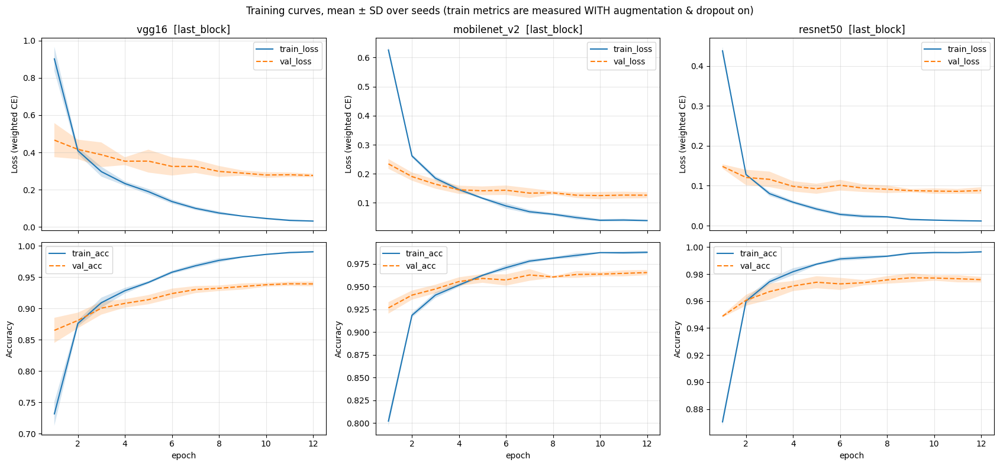

In [34]:
COLORS = {'vgg16': 'tab:blue', 'mobilenet_v2': 'tab:green', 'resnet50': 'tab:red'}
fig, axes = plt.subplots(2, 3, figsize=(17, 8), sharex=True)
for j, arch in enumerate(ARCHS):
    H = {k: np.array([[e[k] for e in RESULTS[('main', arch, s)]['history']] for s in SEEDS])
         for k in ['train_loss', 'val_loss', 'train_acc', 'val_acc']}
    ep = np.arange(1, H['train_loss'].shape[1] + 1)
    for row, (a, b, yl) in enumerate([('train_loss', 'val_loss', 'Loss (weighted CE)'), ('train_acc', 'val_acc', 'Accuracy')]):
        for k, ls in [(a, '-'), (b, '--')]:
            m, s = H[k].mean(0), H[k].std(0, ddof=1)
            axes[row, j].plot(ep, m, ls, label=k); axes[row, j].fill_between(ep, m - s, m + s, alpha=0.2)
        axes[row, j].set_ylabel(yl); axes[row, j].grid(alpha=.3)
        if row == 0: axes[row, j].set_title(f'{arch}  [{BEST_CFG[arch]["strategy"]}]')
        if row == 1: axes[row, j].set_xlabel('epoch')
        axes[row, j].legend()
    gap = (H['train_acc'][:, -1] - H['val_acc'][:, -1]).mean()
    print(f"{arch}: final train acc {H['train_acc'][:, -1].mean():.3f} | val acc {H['val_acc'][:, -1].mean():.3f} | gap {gap:+.3f}")
plt.suptitle('Training curves, mean ± SD over seeds (train metrics are measured WITH augmentation & dropout on)')
plt.tight_layout(); savefig(fig, '6_training_curves'); plt.show()

## 6.3 Overall metrics — mean ± SD on the test set

In [35]:
def agg(arch, key, tag='main', seeds=None):
    return np.array([RESULTS[(tag, arch, s)]['test'][key] for s in (seeds or SEEDS)])

def pm(a, pct=True, d=2):
    a = np.asarray(a, float); k = 100 if pct else 1
    return f"{a.mean()*k:.{d}f} ± {a.std(ddof=1)*k:.{d}f}"

METRICS = [('accuracy', 'Accuracy (%)'), ('balanced_acc', 'Balanced Acc (%)'), ('top3_acc', 'Top-3 Acc (%)'),
           ('macro_precision', 'Macro Precision (%)'), ('macro_recall', 'Macro Recall (%)'),
           ('macro_f1', 'Macro F1 (%)'), ('weighted_f1', 'Weighted F1 (%)')]
rows = {}
for arch in ARCHS:
    r = {name: pm(agg(arch, k)) for k, name in METRICS}
    r['Test NLL'] = pm(agg(arch, 'nll'), pct=False, d=3)
    r['Best epoch'] = pm([RESULTS[('main', arch, s)]['best_epoch'] for s in SEEDS], pct=False, d=1)
    m = build_model(arch, BEST_CFG[arch]['hidden'], BEST_CFG[arch]['dropout'], BEST_CFG[arch]['strategy'], pretrained=False).to(device)
    tot, tr = count_params(m)
    r['Params (M)'], r['Trainable (M)'], r['Latency (ms/img)'] = f"{tot/1e6:.2f}", f"{tr/1e6:.2f}", f"{measure_latency(m):.2f}"
    rows[arch] = r; del m
summary_df = pd.DataFrame(rows).T
summary_df.insert(0, 'strategy', [BEST_CFG[a]['strategy'] for a in ARCHS])
display(summary_df); summary_df.to_csv(OUT_DIR / 'summary_metrics.csv')
print(f"n = {len(SEEDS)} runs per architecture (SD = sample SD, ddof=1)")

,strategy,Accuracy (%),Balanced Acc (%),Top-3 Acc (%),Macro Precision (%),Macro Recall (%),Macro F1 (%),Weighted F1 (%),Test NLL,Best epoch,Params (M),Trainable (M),Latency (ms/img)
vgg16,last_block,92.80 ± 0.14,92.70 ± 0.18,98.56 ± 0.21,92.91 ± 0.14,92.70 ± 0.18,92.76 ± 0.15,92.82 ± 0.12,0.346 ± 0.058,10.4 ± 1.1,27.57,19.93,8.75
mobilenet_v2,last_block,95.31 ± 0.53,95.35 ± 0.52,99.10 ± 0.17,95.42 ± 0.52,95.35 ± 0.52,95.34 ± 0.54,95.34 ± 0.52,0.193 ± 0.015,9.8 ± 2.6,2.55,2.01,1.78
resnet50,last_block,96.61 ± 0.19,96.64 ± 0.20,99.34 ± 0.32,96.68 ± 0.16,96.64 ± 0.20,96.64 ± 0.19,96.62 ± 0.19,0.122 ± 0.008,9.6 ± 0.9,24.56,16.02,5.84


n = 5 runs per architecture (SD = sample SD, ddof=1)


## 6.4 Per-class metrics — mean ± SD


Per-class F1 (%), mean ± SD


,vgg16,mobilenet_v2,resnet50
badminton,87.29 ± 1.58,91.20 ± 0.93,93.86 ± 0.94
basketball,86.86 ± 1.26,92.21 ± 1.34,92.25 ± 1.15
boxing,91.34 ± 1.32,94.70 ± 0.79,94.56 ± 0.57
chess,95.81 ± 0.84,96.01 ± 0.24,97.59 ± 0.48
fencing,94.93 ± 1.28,96.35 ± 0.52,97.37 ± 0.19
formula1,92.99 ± 1.78,95.76 ± 1.40,98.73 ± 0.89
ice_hockey,91.01 ± 0.85,96.02 ± 0.34,97.28 ± 0.65
motogp,98.74 ± 0.50,98.30 ± 0.96,98.99 ± 0.49
shooting,91.92 ± 0.98,95.21 ± 0.43,97.10 ± 0.36
swimming,96.71 ± 0.54,97.60 ± 0.34,98.68 ± 0.61



Per-class Precision (%), mean ± SD


,vgg16,mobilenet_v2,resnet50
badminton,84.23 ± 2.15,87.27 ± 1.62,91.80 ± 1.88
basketball,87.75 ± 3.03,94.40 ± 2.57,92.11 ± 2.95
boxing,91.92 ± 3.54,94.09 ± 1.70,96.39 ± 1.44
chess,94.33 ± 1.70,94.71 ± 0.75,97.09 ± 0.86
fencing,95.52 ± 1.37,98.11 ± 0.88,98.60 ± 0.82
formula1,93.21 ± 3.91,93.65 ± 2.88,97.87 ± 1.26
ice_hockey,92.35 ± 1.85,97.68 ± 0.98,98.06 ± 0.73
motogp,99.34 ± 1.08,100.00 ± 0.00,100.00 ± 0.00
shooting,92.23 ± 1.87,95.88 ± 0.76,96.74 ± 0.81
swimming,98.25 ± 1.21,98.45 ± 0.52,98.13 ± 1.14



Per-class Recall (%), mean ± SD


,vgg16,mobilenet_v2,resnet50
badminton,90.69 ± 3.25,95.52 ± 1.12,96.03 ± 0.47
basketball,86.07 ± 1.30,90.16 ± 1.30,92.46 ± 1.58
boxing,90.87 ± 2.01,95.34 ± 1.06,92.82 ± 0.87
chess,97.35 ± 0.66,97.35 ± 0.40,98.09 ± 0.40
fencing,94.35 ± 1.28,94.66 ± 0.93,96.18 ± 1.08
formula1,92.87 ± 1.77,98.02 ± 0.70,99.60 ± 0.89
ice_hockey,89.74 ± 1.13,94.43 ± 1.32,96.52 ± 0.87
motogp,98.17 ± 0.37,96.67 ± 1.86,98.00 ± 0.95
shooting,91.65 ± 1.62,94.56 ± 1.11,97.48 ± 1.30
swimming,95.24 ± 1.35,96.76 ± 0.52,99.24 ± 0.43


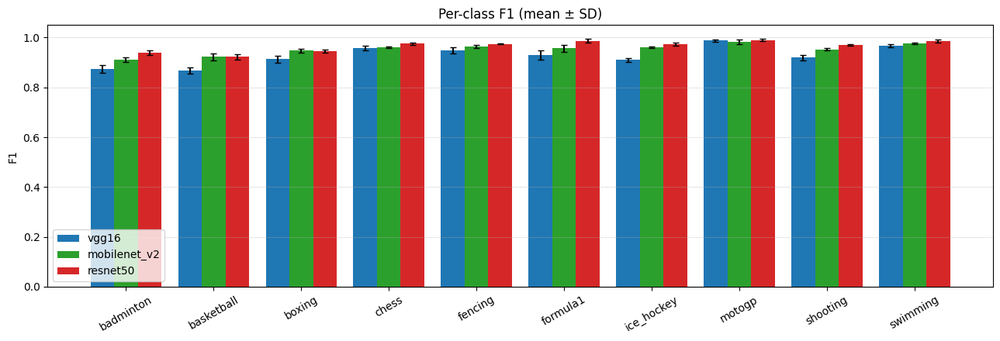

In [36]:
for key, title in [('per_class_f1', 'F1'), ('per_class_precision', 'Precision'), ('per_class_recall', 'Recall')]:
    tbl = pd.DataFrame({a: [pm(np.stack([RESULTS[('main', a, s)]['test'][key] for s in SEEDS])[:, i]) for i in range(K)]
                        for a in ARCHS}, index=CLASSES)
    print(f"\nPer-class {title} (%), mean ± SD"); display(tbl); tbl.to_csv(OUT_DIR / f'perclass_{title.lower()}.csv')

fig, ax = plt.subplots(figsize=(13, 4.5)); w = 0.27
for j, a in enumerate(ARCHS):
    M = np.stack([RESULTS[('main', a, s)]['test']['per_class_f1'] for s in SEEDS])
    ax.bar(np.arange(K) + (j - 1) * w, M.mean(0), w, yerr=M.std(0, ddof=1), capsize=3, label=a, color=COLORS[a])
ax.set_xticks(range(K)); ax.set_xticklabels(CLASSES, rotation=30); ax.set_ylabel('F1'); ax.set_ylim(0, 1.05)
ax.set_title('Per-class F1 (mean ± SD)'); ax.legend(); ax.grid(axis='y', alpha=.3)
plt.tight_layout(); savefig(fig, '6_perclass_f1'); plt.show()

## 6.5 Confusion matrices (row-normalized, averaged over seeds)

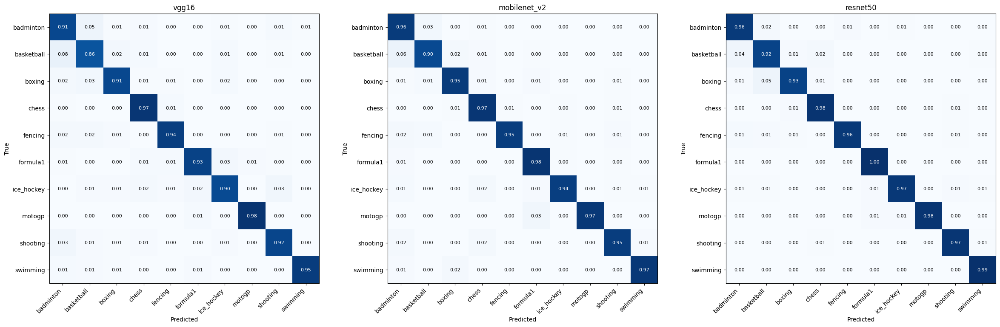

In [37]:
def mean_cm(arch, tag='main'):
    cms = np.stack([RESULTS[(tag, arch, s)]['test']['cm'].astype(float) for s in SEEDS])
    return (cms / cms.sum(2, keepdims=True)).mean(0)

fig, axes = plt.subplots(1, 3, figsize=(24, 7.5))
for ax, a in zip(axes, ARCHS):
    cm = mean_cm(a); ax.imshow(cm, cmap='Blues', vmin=0, vmax=1)
    ax.set_xticks(range(K)); ax.set_yticks(range(K)); ax.set_xticklabels(CLASSES, rotation=45, ha='right'); ax.set_yticklabels(CLASSES)
    for i in range(K):
        for j in range(K):
            ax.text(j, i, f"{cm[i, j]:.2f}", ha='center', va='center', fontsize=8, color='white' if cm[i, j] > .5 else 'black')
    ax.set_title(a); ax.set_xlabel('Predicted'); ax.set_ylabel('True')
plt.tight_layout(); savefig(fig, '6_confusion'); plt.show()

## 6.6 Statistical significance (p-value)
**Welch's t-test** (two-sided, no equal-variance assumption) for every pair of architectures on test accuracy and Macro-F1 over the n seeds.
Bonferroni correction for 3 pairs × 2 metrics = 6 tests → threshold α = 0.05/6 ≈ 0.0083.
> Caveat: n is small (3–10), so the statistical power is low, and different seeds only measure the variation from initialization / training randomness on the same test set, not the variation from sampling the data.

In [38]:
from itertools import combinations
PVAL_METRICS = [('accuracy', 'Accuracy'), ('macro_f1', 'Macro F1')]
pairs = list(combinations(ARCHS, 2)); alpha_bonf = 0.05 / (len(pairs) * len(PVAL_METRICS))   # 3 pairs x 2 metrics = 6 tests
def welch_t(a, b):
    # Welch's t-test; (nan, nan) when both groups are constant across seeds -> the test is undefined
    a, b = np.round(np.asarray(a, float), 10), np.round(np.asarray(b, float), 10)   # drop float noise
    if a.std() == 0 and b.std() == 0: return float('nan'), float('nan')
    t, p = stats.ttest_ind(a, b, equal_var=False); return float(t), float(p)

rows = []
for key, name in PVAL_METRICS:
    for a, b in pairs:
        xa, xb = agg(a, key), agg(b, key)
        t, p = welch_t(xa, xb)
        rows.append({'metric': name, 'A': a, 'B': b, 'mean A (%)': xa.mean() * 100, 'mean B (%)': xb.mean() * 100,
                     'diff A-B (pp)': (xa.mean() - xb.mean()) * 100, 't': t, 'p-value': p,
                     'sig @0.05': p < 0.05, f'sig @Bonferroni ({alpha_bonf:.4f})': p < alpha_bonf})
pval_df = pd.DataFrame(rows).round(4); display(pval_df); pval_df.to_csv(OUT_DIR / 'pvalues.csv', index=False)

,metric,A,B,mean A (%),mean B (%),diff A-B (pp),t,p-value,sig @0.05,sig @Bonferroni (0.0083)
0,Accuracy,vgg16,mobilenet_v2,92.7951,95.3125,-2.5174,-10.2530,0.0003,True,True
1,Accuracy,vgg16,resnet50,92.7951,96.6146,-3.8194,-35.9258,0.0000,True,True
2,Accuracy,mobilenet_v2,resnet50,95.3125,96.6146,-1.3021,-5.1450,0.0035,True,True
3,Macro F1,vgg16,mobilenet_v2,92.7607,95.3359,-2.5752,-10.3598,0.0002,True,True
4,Macro F1,vgg16,resnet50,92.7607,96.6395,-3.8788,-36.4473,0.0000,True,True
5,Macro F1,mobilenet_v2,resnet50,95.3359,96.6395,-1.3036,-5.1436,0.0037,True,True


# 7. Discussion and conclusions

## 7.1 Which model is best? (auto-summary — use it when writing the conclusions)

In [39]:
mf = {a: agg(a, 'macro_f1') for a in ARCHS}
rank = sorted(ARCHS, key=lambda a: -mf[a].mean())
print("Ranking by mean test Macro-F1:")
for i, a in enumerate(rank, 1): print(f"  {i}. {a:13s} {pm(mf[a])} %")
best, worst = rank[0], rank[-1]
for other in rank[1:]:
    p = welch_t(mf[best], mf[other])[1]
    verdict = ('t-test undefined (no variation across seeds)' if np.isnan(p) else 'significant' if p < alpha_bonf
               else 'significant only without correction' if p < 0.05 else 'NOT significant')
    print(f"  {best} vs {other}: p = {p:.4f} -> {verdict} (Bonferroni α={alpha_bonf:.4f})")
print(f"\nBest: {best} | Worst: {worst}")

print("\n--- Anomaly checks ---")
for a in ARCHS:
    v = mf[a]; ep = [RESULTS[('main', a, s)]['best_epoch'] for s in SEEDS]
    flags = []
    if (v.max() - v.min()) > 0.03: flags.append(f"seed range of Macro-F1 = {(v.max()-v.min())*100:.1f} pp (unstable across seeds)")
    if np.mean(np.array(ep) >= EPOCHS - 1) > 0.5: flags.append("best epoch at the end of training in most seeds -> possibly under-trained")
    gap = np.mean([RESULTS[('main', a, s)]['history'][-1]['train_acc'] - RESULTS[('main', a, s)]['history'][-1]['val_acc'] for s in SEEDS])
    if gap > 0.10: flags.append(f"train-val accuracy gap {gap:.2f} -> overfitting")
    print(f"{a:13s}: per-seed macro-F1 = {np.round(v*100, 2).tolist()} | best epochs = {ep} | " + ("; ".join(flags) if flags else "no anomaly flagged"))

print("\n--- Weakest classes (mean per-class F1) and most-confused pairs ---")
for a in ARCHS:
    f1c = np.stack([RESULTS[('main', a, s)]['test']['per_class_f1'] for s in SEEDS]).mean(0)
    cm = mean_cm(a); off = [(cm[i, j], CLASSES[i], CLASSES[j]) for i in range(K) for j in range(K) if i != j]
    off = sorted(off, reverse=True)[:3]
    print(f"{a:13s}: weakest = {[(CLASSES[i], round(float(f1c[i]), 3)) for i in np.argsort(f1c)[:3]]} | "
          f"top confusions (true->pred, rate) = {[(t + '->' + p, round(float(r), 3)) for r, t, p in off]}")

Ranking by mean test Macro-F1:
  1. resnet50      96.64 ± 0.19 %
  2. mobilenet_v2  95.34 ± 0.54 %
  3. vgg16         92.76 ± 0.15 %
  resnet50 vs mobilenet_v2: p = 0.0037 -> significant (Bonferroni α=0.0083)
  resnet50 vs vgg16: p = 0.0000 -> significant (Bonferroni α=0.0083)

Best: resnet50 | Worst: vgg16

--- Anomaly checks ---
vgg16        : per-seed macro-F1 = [92.94, 92.79, 92.57, 92.86, 92.65] | best epochs = [12, 9, 10, 10, 11] | no anomaly flagged
mobilenet_v2 : per-seed macro-F1 = [95.51, 95.25, 95.58, 94.46, 95.87] | best epochs = [12, 7, 11, 7, 12] | best epoch at the end of training in most seeds -> possibly under-trained
resnet50     : per-seed macro-F1 = [96.41, 96.91, 96.64, 96.53, 96.71] | best epochs = [9, 11, 9, 9, 10] | no anomaly flagged

--- Weakest classes (mean per-class F1) and most-confused pairs ---
vgg16        : weakest = [('basketball', 0.869), ('badminton', 0.873), ('ice_hockey', 0.91)] | top confusions (true->pred, rate) = [('basketball->badminton', 0.07

> ✏️ **Write the group's conclusions here (based only on the numbers above):**
> - Which model is best / worst on Macro-F1, and is the difference statistically significant (p-value)?
> - Which model fits our use case best when weighing accuracy vs. model size vs. latency?
> - Anomalies found (from the anomaly checks), their likely causes and how to address them in future work

## 7.2 Grad-CAM analysis
Grad-CAM (library `pytorch-grad-cam`, as in example CNN2_ex4) on the model of the **best seed of each architecture — chosen by val macro-F1, not by test** — on the same test images, with target = the predicted class.
Target layer: VGG16 `features[-1]`, ResNet50 `layer4[-1]`, MobileNetV2 `features[-1]`
- Top rows = images that **all models classify correctly** (check that they are right for the right reason, e.g. looking at the athlete / equipment / venue, not the background or a watermark)
- Bottom rows = images that **at least one model gets wrong** (error analysis)

Best seed per architecture (by val macro-F1): {'vgg16': 0, 'mobilenet_v2': 1, 'resnet50': 0}
4 all-correct examples, 4 examples with >=1 wrong model


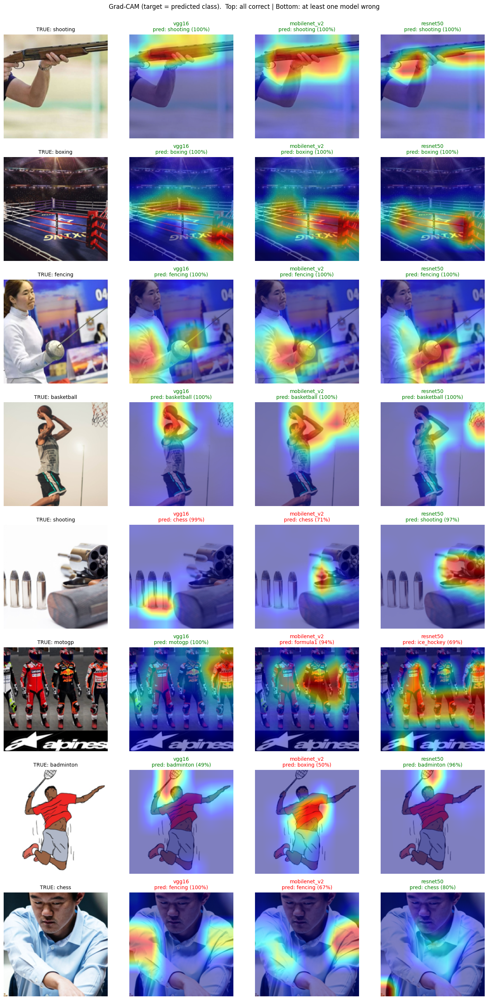

In [40]:
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image

best_seed = {a: max(SEEDS, key=lambda s: RESULTS[('main', a, s)]['best_val_f1']) for a in ARCHS}   # chosen on VAL, not test
print("Best seed per architecture (by val macro-F1):", best_seed)

def load_final_model(arch, seed, tag='main'):
    cfg = RESULTS[(tag, arch, seed)]['cfg']
    m = build_model(arch, cfg['hidden'], cfg['dropout'], cfg['strategy'], pretrained=False).to(device)
    m.load_state_dict(torch.load(OUT_DIR / 'ckpt' / f'{tag}_{arch}_seed{seed}.pt', map_location=device))
    for p in m.parameters(): p.requires_grad_(True)      # frozen layers must allow gradient flow for Grad-CAM
    return m.eval()

FINAL = {a: load_final_model(a, best_seed[a]) for a in ARCHS}
TARGET_LAYER = {'vgg16': lambda m: m.features[-1], 'resnet50': lambda m: m.layer4[-1], 'mobilenet_v2': lambda m: m.features[-1]}
view_transform = T.Compose([T.Resize(256, antialias=True), T.CenterCrop(IMG_SIZE)])   # same crop as val_transform, for the overlay

def gradcam_overlay(arch, pil, class_idx):
    x = val_transform(pil).unsqueeze(0).to(device)
    rgb = np.float32(np.asarray(view_transform(pil))) / 255.0
    cam = GradCAM(model=FINAL[arch], target_layers=[TARGET_LAYER[arch](FINAL[arch])])
    mask = cam(input_tensor=x, targets=[ClassifierOutputTarget(int(class_idx))])[0]
    cam.activations_and_grads.release()
    return show_cam_on_image(rgb, mask, use_rgb=True)

# ---- choose example test images ----
y_true = RESULTS[('main', ARCHS[0], SEEDS[0])]['y_true']
preds = {a: RESULTS[('main', a, best_seed[a])]['y_pred'] for a in ARCHS}
probs = {a: RESULTS[('main', a, best_seed[a])]['probs'] for a in ARCHS}
all_ok = np.all([preds[a] == y_true for a in ARCHS], axis=0)
rng = np.random.default_rng(0)

def pick_distinct_classes(mask, n):
    idx = np.where(mask)[0]; rng.shuffle(idx); chosen, used = [], set()
    for i in idx:
        if y_true[i] not in used: chosen.append(int(i)); used.add(y_true[i])
        if len(chosen) == n: break
    return chosen

EX_OK, EX_ERR = pick_distinct_classes(all_ok, 4), pick_distinct_classes(~all_ok, 4)
EXAMPLES = EX_OK + EX_ERR
print(f"{len(EX_OK)} all-correct examples, {len(EX_ERR)} examples with >=1 wrong model")

assert EXAMPLES, "no test images to show"
fig, axes = plt.subplots(len(EXAMPLES), 4, figsize=(14, 3.4 * len(EXAMPLES)), squeeze=False)
for r, i in enumerate(EXAMPLES):
    pil = Image.open(test_df.path[i]).convert('RGB')
    axes[r, 0].imshow(view_transform(pil)); axes[r, 0].set_title(f"TRUE: {CLASSES[y_true[i]]}", fontsize=10)
    for c, a in enumerate(ARCHS, 1):
        pr = int(preds[a][i]); axes[r, c].imshow(gradcam_overlay(a, pil, pr))
        axes[r, c].set_title(f"{a}\npred: {CLASSES[pr]} ({probs[a][i].max()*100:.0f}%)", fontsize=10,
                             color='green' if pr == y_true[i] else 'red')
for a in axes.ravel(): a.axis('off')
plt.suptitle('Grad-CAM (target = predicted class).  Top: all correct | Bottom: at least one model wrong', y=1.0)
plt.tight_layout(); savefig(fig, '7_gradcam'); plt.show()

> ✏️ **Write the Grad-CAM analysis:** is the heatmap on the objects that matter (athlete / ball / racket / car / chessboard) or on the background / text / spectators? Do the architectures look at different regions? For misclassified images, does the model look at the wrong place?

## 7.3 Eyeball analysis — pre-trained vs. fine-tuned models
On the same images, compare the predictions of the **pre-trained ImageNet models (no training; top-1 of the original 1,000 classes)** with **each of our fine-tuned models**.

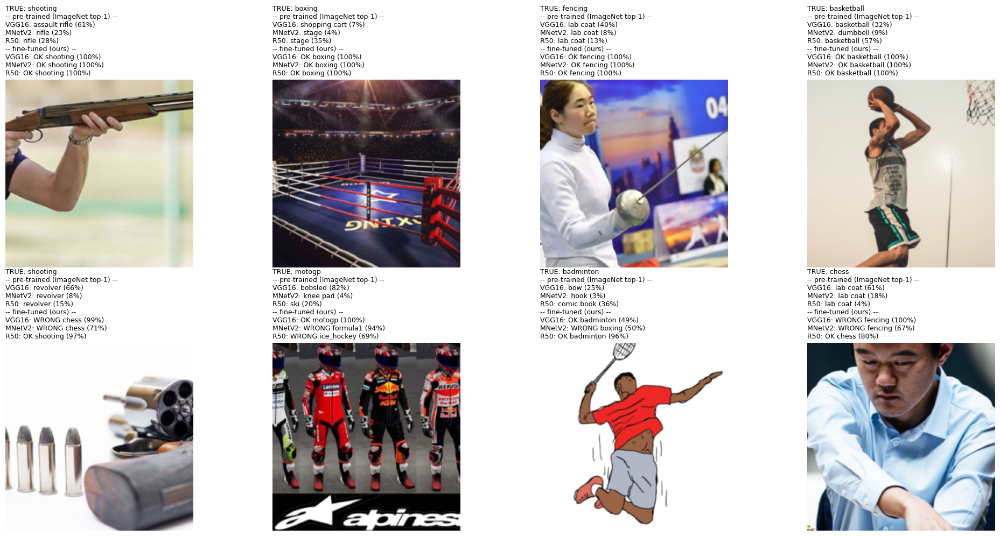

In [41]:
short = {'vgg16': 'VGG16', 'mobilenet_v2': 'MNetV2', 'resnet50': 'R50'}
nrows = max(1, math.ceil(len(EXAMPLES) / 4))
fig, axes = plt.subplots(nrows, 4, figsize=(20, 5 * nrows), squeeze=False)
for ax in axes.ravel(): ax.axis('off')
for ax, i in zip(axes.ravel(), EXAMPLES):
    pil = Image.open(test_df.path[i]).convert('RGB'); ax.imshow(view_transform(pil)); ax.axis('off')
    lines = [f"TRUE: {CLASSES[y_true[i]]}", "-- pre-trained (ImageNet top-1) --"]
    for a in ARCHS:
        n, p = imagenet_topk(a, pil, 1)[0]; lines.append(f"{short[a]}: {n[:18]} ({p*100:.0f}%)")
    lines.append("-- fine-tuned (ours) --")
    for a in ARCHS:
        pr = int(preds[a][i]); lines.append(f"{short[a]}: {'OK ' if pr == y_true[i] else 'WRONG '}{CLASSES[pr]} ({probs[a][i].max()*100:.0f}%)")
    ax.set_title("\n".join(lines), fontsize=9, loc='left')
plt.tight_layout(); savefig(fig, '7_eyeball'); plt.show()

## 7.4 Error analysis — weakest class of the best architecture

Best architecture: resnet50 | weakest class: basketball (mean F1 = 0.922)


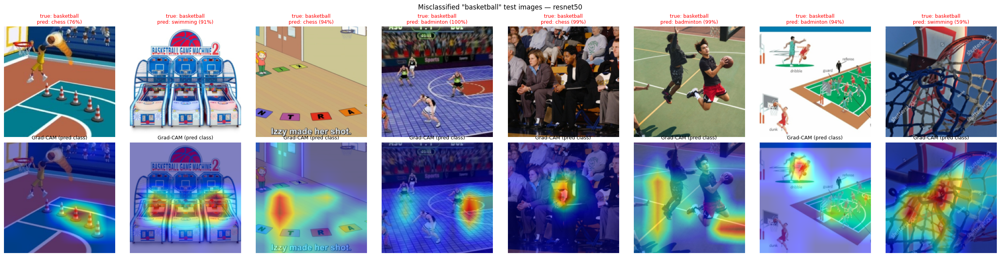

In [42]:
best_arch = rank[0]
f1c = np.stack([RESULTS[('main', best_arch, s)]['test']['per_class_f1'] for s in SEEDS]).mean(0)
worst_cls = int(np.argmin(f1c))
print(f"Best architecture: {best_arch} | weakest class: {CLASSES[worst_cls]} (mean F1 = {f1c[worst_cls]:.3f})")

wrong = np.where((y_true == worst_cls) & (RESULTS[('main', best_arch, best_seed[best_arch])]['y_pred'] != worst_cls))[0][:8]
pb = RESULTS[('main', best_arch, best_seed[best_arch])]
if len(wrong) == 0:
    print("No misclassified test images of this class for the best seed — inspect another class/seed.")
else:
    fig, axes = plt.subplots(2, len(wrong), figsize=(3.2 * len(wrong), 6.6), squeeze=False)
    for j, i in enumerate(wrong):
        pil = Image.open(test_df.path[i]).convert('RGB'); pr = int(pb['y_pred'][i])
        axes[0, j].imshow(view_transform(pil)); axes[0, j].set_title(f"true: {CLASSES[worst_cls]}\npred: {CLASSES[pr]} ({pb['probs'][i].max()*100:.0f}%)", fontsize=9, color='red')
        axes[1, j].imshow(gradcam_overlay(best_arch, pil, pr)); axes[1, j].set_title('Grad-CAM (pred class)', fontsize=9)
        axes[0, j].axis('off'); axes[1, j].axis('off')
    plt.suptitle(f'Misclassified "{CLASSES[worst_cls]}" test images — {best_arch}'); plt.tight_layout()
    savefig(fig, '7_error_analysis'); plt.show()

> ✏️ **Write the error analysis:** (1) the weakest class and the most frequently confused pairs (see Section 7.1 and the confusion matrices); (2) look at the misclassified images and identify the likely causes, e.g. visually similar classes, several sports in one image, unusual camera angles, wrong labels, similar backgrounds; (3) future fixes, e.g. collecting more images / hard examples, cleaning the labels, higher resolution, different augmentation, unfreezing more layers.

## 7.5 Ablation study — frozen backbone vs. fine-tuning the last block (5 seeds each, Welch + 95% CI)
Compare `frozen` (transfer learning) with `last_block` (fine-tuning). Each strategy uses the best config from its own sweep (same budget) and is re-trained with the same `SEEDS`; the comparison is on the **test set**: mean difference (last_block − frozen) with a Welch 95% CI, p-value (Bonferroni-corrected over the architectures; Macro-F1 is the primary metric, accuracy is secondary) and Cohen's d.
**Limitation:** the CI / p-value reflect only training randomness (initialization, batch order, augmentation), because the train/val/test split is fixed and each sweep uses a single seed.

frozen (mean ± SD) [95% CI] %  \
metric        arch                                         
test macro-F1 vgg16          92.48 ± 0.35 [92.05, 92.91]   
              mobilenet_v2   93.34 ± 0.42 [92.82, 93.87]   
              resnet50       96.25 ± 0.15 [96.07, 96.43]   
test accuracy vgg16          92.50 ± 0.36 [92.05, 92.95]   
              mobilenet_v2   93.37 ± 0.43 [92.84, 93.90]   
              resnet50       96.20 ± 0.16 [96.01, 96.39]   

                           last_block (mean ± SD) [95% CI] %  \
metric        arch                                             
test macro-F1 vgg16              92.76 ± 0.15 [92.58, 92.95]   
              mobilenet_v2       95.34 ± 0.54 [94.67, 96.00]   
              resnet50           96.64 ± 0.19 [96.41, 96.87]   
test accuracy vgg16              92.80 ± 0.14 [92.62, 92.97]   
              mobilenet_v2       95.31 ± 0.53 [94.65, 95.97]   
              resnet50           96.61 ± 0.19 [96.37, 96.86]   

                           diff LB−FZ (pp) [95% CI]  p (Welch)  \
metric        arch                                               
test macro-F1 vgg16            +0.28 [-0.15, +0.70]     0.1553   
              mobilenet_v2     +1.99 [+1.28, +2.70]     0.0002   
              resnet50         +0.39 [+0.14, +0.63]     0.0070   
test accuracy vgg16            +0.30 [-0.15, +0.74]     0.1467   
              mobilenet_v2     +1.94 [+1.24, +2.65]     0.0003   
              resnet50         +0.42 [+0.16, +0.68]     0.0061   

                            p adj (Bonferroni ×3)  Cohen's d  
metric        arch                                            
test macro-F1 vgg16                        0.4660       1.04  
              mobilenet_v2                 0.0007       4.13  
              resnet50                     0.0209       2.32  
test accuracy vgg16                        0.4402       1.08  
              mobilenet_v2                 0.0008       4.03  
              resnet50                     0.0184       2.37

n = 5 seeds per strategy | lr chosen per strategy on val | CI = Welch t-interval of the mean difference
vgg16        : LB−FZ = +0.28 pp [-0.15, +0.70], p_adj = 0.4660 -> no significant difference
mobilenet_v2 : LB−FZ = +1.99 pp [+1.28, +2.70], p_adj = 0.0007 -> last_block better
resnet50     : LB−FZ = +0.39 pp [+0.14, +0.63], p_adj = 0.0209 -> last_block better


,mean Δ (pp),SD Δ (pp),95% CI Δ (pp),p (paired t),"corr(FZ, LB) over seeds"
arch,,,,,
vgg16,0.28,0.37,"[-0.19, +0.74]",0.1719,0.02
mobilenet_v2,1.99,0.23,"[+1.71, +2.28]",0.0000,0.91
resnet50,0.39,0.22,"[+0.11, +0.66]",0.0179,0.11


Paired test has fewer df than Welch: use it only if corr > 0 (same seed != same init when hidden/dropout differ). Welch above is the primary result.


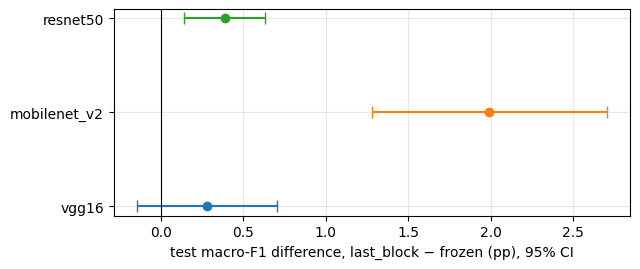

In [43]:
from scipy import stats

def mean_ci(x, conf=0.95):
    x = np.asarray(x, float); h = stats.t.ppf(0.5 + conf / 2, len(x) - 1) * x.std(ddof=1) / np.sqrt(len(x))
    return x.mean() - h, x.mean() + h

def welch_ci(a, b, conf=0.95):             # a - b ; Welch-Satterthwaite df
    a, b = np.round(np.asarray(a, float), 10), np.round(np.asarray(b, float), 10)   # drop float noise
    na, nb, va, vb = len(a), len(b), a.var(ddof=1), b.var(ddof=1)
    if va == 0 and vb == 0:                 # constant across seeds -> CI, p-value and Cohen's d are undefined
        nan = float('nan'); return dict(diff=a.mean() - b.mean(), lo=nan, hi=nan, p=nan, df=nan, d=nan)
    diff, se = a.mean() - b.mean(), np.sqrt(va / na + vb / nb)
    df = (va / na + vb / nb) ** 2 / ((va / na) ** 2 / (na - 1) + (vb / nb) ** 2 / (nb - 1))
    tc = stats.t.ppf(0.5 + conf / 2, df); _, p = stats.ttest_ind(a, b, equal_var=False)
    sp = np.sqrt(((na - 1) * va + (nb - 1) * vb) / (na + nb - 2))
    return dict(diff=diff, lo=diff - tc * se, hi=diff + tc * se, p=p, df=df, d=diff / sp)

M = len(ARCHS)                              # Bonferroni over the architectures
rows, forest = [], {}
for key, name in [('macro_f1', 'test macro-F1'), ('accuracy', 'test accuracy')]:
    for arch in ARCHS:
        fz, lb = agg(arch, key, TAG_S['frozen']), agg(arch, key, TAG_S['last_block'])
        r = welch_ci(lb, fz)                # positive diff = last_block better
        if key == 'macro_f1': forest[arch] = r
        rows.append({'metric': name, 'arch': arch,
                     'frozen (mean ± SD) [95% CI] %': f"{fz.mean()*100:.2f} ± {fz.std(ddof=1)*100:.2f} [{mean_ci(fz)[0]*100:.2f}, {mean_ci(fz)[1]*100:.2f}]",
                     'last_block (mean ± SD) [95% CI] %': f"{lb.mean()*100:.2f} ± {lb.std(ddof=1)*100:.2f} [{mean_ci(lb)[0]*100:.2f}, {mean_ci(lb)[1]*100:.2f}]",
                     'diff LB−FZ (pp) [95% CI]': f"{r['diff']*100:+.2f} [{r['lo']*100:+.2f}, {r['hi']*100:+.2f}]",
                     'p (Welch)': round(r['p'], 4), f'p adj (Bonferroni ×{M})': round(min(r['p'] * M, 1), 4), "Cohen's d": round(r['d'], 2)})
cmp_df = pd.DataFrame(rows).set_index(['metric', 'arch']); display(cmp_df); cmp_df.to_csv(OUT_DIR / 'strategy_comparison.csv')
print(f"n = {len(SEEDS)} seeds per strategy | lr chosen per strategy on val | CI = Welch t-interval of the mean difference")

for arch in ARCHS:
    r = forest[arch]; padj = min(r['p'] * M, 1)
    verdict = ('undefined (no variation across seeds)' if np.isnan(r['p']) else
               ('last_block better' if r['diff'] > 0 else 'frozen better') if padj < 0.05 else 'no significant difference')
    print(f"{arch:13s}: LB−FZ = {r['diff']*100:+.2f} pp [{r['lo']*100:+.2f}, {r['hi']*100:+.2f}], p_adj = {padj:.4f} -> {verdict}")

# supplementary: paired by seed (meaningful only if scores of the same seed are positively correlated)
rows_p = []
for arch in ARCHS:
    fz, lb = agg(arch, 'macro_f1', TAG_S['frozen']), agg(arch, 'macro_f1', TAG_S['last_block'])
    fz, lb = np.round(fz, 10), np.round(lb, 10)
    dl = lb - fz; n = len(dl); h = stats.t.ppf(0.975, n - 1) * dl.std(ddof=1) / np.sqrt(n)
    rows_p.append({'arch': arch, 'mean Δ (pp)': round(dl.mean() * 100, 2), 'SD Δ (pp)': round(dl.std(ddof=1) * 100, 2),
                   '95% CI Δ (pp)': f"[{(dl.mean() - h) * 100:+.2f}, {(dl.mean() + h) * 100:+.2f}]",
                   'p (paired t)': np.nan if dl.std() == 0 else round(stats.ttest_rel(lb, fz).pvalue, 4),
                   'corr(FZ, LB) over seeds': np.nan if min(fz.std(), lb.std()) == 0 else round(float(np.corrcoef(fz, lb)[0, 1]), 2)})
display(pd.DataFrame(rows_p).set_index('arch'))
print('Paired test has fewer df than Welch: use it only if corr > 0 (same seed != same init when hidden/dropout differ). Welch above is the primary result.')

fig, ax = plt.subplots(figsize=(6.5, 2.8))
for i, arch in enumerate(ARCHS):
    r = forest[arch]; ax.errorbar(r['diff'] * 100, i, xerr=[[(r['diff'] - r['lo']) * 100], [(r['hi'] - r['diff']) * 100]], fmt='o', capsize=4)
ax.axvline(0, c='k', lw=.8); ax.set_yticks(range(M)); ax.set_yticklabels(ARCHS)
ax.set_xlabel('test macro-F1 difference, last_block − frozen (pp), 95% CI'); ax.grid(alpha=.3)
plt.tight_layout(); savefig(fig, '7x_strategy_diff'); plt.show()

---
# Submission checklist (HOMEWORK_GUIDELINE, item 6)
1. `HW_<group name>_member.pdf` — member names, photos and responsibilities
2. `HW_<group name>_finding.pdf` — presentation slides (all figures/tables are saved automatically in `outputs/figs/` and `outputs/*.csv`), ordered by Sections 1–7 of this notebook (~5-minute presentation)
3. (Optional) `HW_<group name>_presentation.mp4`
4. Other files, e.g. the link to the W&B project (`DADS7202_HW_SportCNN`) and this notebook — **make sure no API key is left in the notebook before sharing it**